# Indego Trips: Predicting Long-Duration Rides

**Project scaffold:** Can checkout-time information from 2024–2025 predict whether a trip in 2026 exceeds 20 minutes? This notebook contains a project workflow; the data overview is implemented and later analysis and modeling sections remain placeholders.

Run from this folder using the project environment: `python -m pip install -r requirements.txt`, then `python -m jupyter lab`. Select the kernel belonging to `.venv`. Quarterly CSVs remain unchanged in the data folder; Section 2 creates a combined cache if needed.

Each team member should document the **question, method, result, and interpretation** for their own sections. Results and conclusions are intentionally left blank.

## Setup and Reproducibility

Import planned libraries, define the random seed and local paths. Add reusable utilities when needed.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import polars as pl
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath
from matplotlib.patches import Polygon, Patch
import seaborn as sns
import json
import time
from datetime import datetime

from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, precision_recall_curve, RocCurveDisplay)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import ConfusionMatrixDisplay

RANDOM_STATE = 5450

## 1. Introduction and Background

### 1.1 Motivation

When an Indego bike is in use, it is unavailable for another trip. Understanding which trips are likely to last longer can therefore provide a useful perspective on bike availability and fleet turnover.

This project examines whether information available at checkout can help identify long-duration trips. By learning from historical trip records and evaluating predictions on a later operating period, we connect rider, bike, and trip-start characteristics to a practical question for bike-share planning.

### 1.2 Prediction Objective

Our primary research question is:

**Can checkout-time information from 2024 and 2025 predict whether an Indego trip in 2026 will last more than 20 minutes?**

We define a **long ride** as a trip lasting strictly more than 20 minutes; a trip lasting exactly 20 minutes is not classified as long. We will verify the source duration units before constructing the target.

The planned evaluation follows the order in which trips occur: 2024 and 2025 form the training period, 2026 Q1 and Q2 form the validation period, and 2026 Q3 is reserved for final testing. Predictors will use information available at checkout; trip duration will define the outcome.

### 1.3 Supporting Research Questions

1. How do long-ride rates vary across passholder types?
2. How do long-ride rates compare between morning rush (7:00 to 9:59) and evening rush (16:00 to 18:59)?
3. How do long-ride rates vary by bike type?
4. Which checkout-time characteristics provide useful information for predicting long rides?
5. How well do Logistic Regression, Random Forest, and Gradient Boosting predict trips in a later operating period?

Together, these questions connect patterns in rider and trip characteristics with the ability to predict long rides in a future period.

## 2. Data Preparation

This section combines the 11 quarterly Indego trip files from 2024 Q1 through 2026 Q3, inspects the dataset, and prepares a working table for cleaning and modeling. The original quarterly files remain unchanged.

### 2.1 Load or Create the Combined Dataset

Load `data/full_data.csv` if it exists. Otherwise, convert 2026 Q3 timestamps to month/day/year format, preserving seconds, before combining the quarterly files. The original CSVs remain unchanged. When loading the combined data, treat the source `NULL` passholder label as missing.

In [2]:
DATA_DIR = Path("data")
FULL_DATA_PATH = DATA_DIR / "full_data.csv"

if not FULL_DATA_PATH.exists():
    quarter_data = []
    for path in sorted(DATA_DIR.glob("indego-trips-*.csv")):
        year, quarter = re.search(r"(\d{4})-q([1-4])", path.name, re.IGNORECASE).groups()
        trips = pl.scan_csv(path, infer_schema=False)
        if (year, quarter) == ("2026", "3"):
            trips = trips.with_columns(
                pl.col("start_time", "end_time")
                .str.to_datetime("%Y-%m-%d %H:%M:%S", strict=True)
                .dt.strftime("%m/%d/%Y %H:%M:%S")
            )
        trips = trips.with_columns(
            pl.lit(int(year)).alias("source_year"),
            pl.lit(int(quarter)).alias("source_quarter"),
        )
        quarter_data.append(trips)
    pl.concat(quarter_data).sink_csv(FULL_DATA_PATH)
    print(f"Created {FULL_DATA_PATH} from {len(quarter_data)} quarterly files.")
else:
    print(f"Found {FULL_DATA_PATH}.")

full_data = pl.scan_csv(FULL_DATA_PATH, infer_schema=False, null_values={"passholder_type": "NULL"})

Created data/full_data.csv from 11 quarterly files.


### 2.2 Dataset Overview and Summary

Inspect the shape, columns, sample rows, missing values, and summary statistics. Numeric fields are converted for the summary; the saved CSV remains unchanged.

In [3]:
print("Shape (rows, columns):", (full_data.select(pl.len()).collect().item(), len(full_data.collect_schema())))
full_data.head().collect()

Shape (rows, columns): (3858309, 17)


trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type,source_year,source_quarter
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""820756378""","""7""","""1/1/2024 0:04""","""1/1/2024 0:11""","""3125""","""39.943909""","""-75.167351""","""3010""","""39.947109""","""-75.166183""","""23172""","""30""","""One Way""","""Indego30""","""electric""","""2024""","""1"""
"""820756236""","""1""","""1/1/2024 0:04""","""1/1/2024 0:05""","""3068""","""39.93549""","""-75.167107""","""3068""","""39.93549""","""-75.167107""","""14667""","""30""","""Round Trip""","""Indego30""","""standard""","""2024""","""1"""
"""820756358""","""5""","""1/1/2024 0:05""","""1/1/2024 0:10""","""3068""","""39.93549""","""-75.167107""","""3086""","""39.940189""","""-75.166908""","""14667""","""30""","""One Way""","""Indego30""","""standard""","""2024""","""1"""
"""820756551""","""9""","""1/1/2024 0:08""","""1/1/2024 0:17""","""3049""","""39.945091""","""-75.142502""","""3063""","""39.946331""","""-75.1698""","""22420""","""30""","""One Way""","""Indego30""","""electric""","""2024""","""1"""
"""820886236""","""600""","""1/1/2024 0:11""","""1/1/2024 10:11""","""3010""","""39.947109""","""-75.166183""","""3236""","""39.96566""","""-75.17765""","""23095""","""30""","""One Way""","""Indego30""","""electric""","""2024""","""1"""


In [4]:
# Describe numeric trip fields.
num_col = ["duration", "start_lat", "start_lon", "end_lat", "end_lon", "plan_duration"]
full_data.select(pl.col(num_col).cast(pl.Float64, strict=False)).collect().describe()

statistic,duration,start_lat,start_lon,end_lat,end_lon,plan_duration
str,f64,f64,f64,f64,f64,f64
"""count""",3.858309e6,3.858193e6,3.858193e6,3.79924e6,3.79924e6,3.858309e6
"""null_count""",0.0,116.0,116.0,59069.0,59069.0,0.0
"""mean""",16.647133,39.952282,-75.168915,39.952216,-75.16871,148.299131
"""std""",52.788842,0.015423,0.018646,0.015521,0.01873,163.364884
"""min""",1.0,39.007729,-75.249001,39.007729,-75.249001,1.0
"""25%""",6.0,39.943909,-75.17971,39.943909,-75.17971,30.0
"""50%""",10.0,39.95134,-75.16758,39.95134,-75.167381,30.0
"""75%""",16.0,39.96006,-75.156952,39.959999,-75.156723,365.0
"""max""",1440.0,40.030548,-75.101212,40.030548,-75.101212,365.0


### 2.3 Select Columns for Analysis

Remove destination and post-trip fields from the working table. Keep trip ID and source information for data checks, duration for the target, and checkout-time fields for analysis. Trip ID and source metadata will not be used as model predictors. The saved combined CSV keeps all original fields.

In [5]:
# exclude colums we want to remove
col_drop = ["end_time", "end_station", "end_lat", "end_lon", "bike_id", "trip_route_category"]
analysis_data = full_data.drop(col_drop)
analysis_data.head().collect()

trip_id,duration,start_time,start_station,start_lat,start_lon,plan_duration,passholder_type,bike_type,source_year,source_quarter
str,str,str,str,str,str,str,str,str,str,str
"""820756378""","""7""","""1/1/2024 0:04""","""3125""","""39.943909""","""-75.167351""","""30""","""Indego30""","""electric""","""2024""","""1"""
"""820756236""","""1""","""1/1/2024 0:04""","""3068""","""39.93549""","""-75.167107""","""30""","""Indego30""","""standard""","""2024""","""1"""
"""820756358""","""5""","""1/1/2024 0:05""","""3068""","""39.93549""","""-75.167107""","""30""","""Indego30""","""standard""","""2024""","""1"""
"""820756551""","""9""","""1/1/2024 0:08""","""3049""","""39.945091""","""-75.142502""","""30""","""Indego30""","""electric""","""2024""","""1"""
"""820886236""","""600""","""1/1/2024 0:11""","""3010""","""39.947109""","""-75.166183""","""30""","""Indego30""","""electric""","""2024""","""1"""


### 2.4 Data Validity and Cleaning

Convert fields to appropriate types, inspect data quality, and drop missing values from retained analysis columns. The source `NULL` passholder label is treated as missing.

#### 2.4.1 Convert Types and Inspect Data Quality

Parse month/day/year timestamps, accepting both minute and second precision. Convert numeric columns and inspect null values, duplicate trip IDs, and nonpositive durations.

In [6]:
typed_data = analysis_data.with_columns(
    pl.coalesce(
        # convert times
        pl.col("start_time").str.to_datetime("%m/%d/%Y %H:%M:%S", strict=False),
        pl.col("start_time").str.to_datetime("%m/%d/%Y %H:%M", strict=False),
    ).alias("start_time"),
    # convert to float
    pl.col("duration", "start_lat", "start_lon", "plan_duration").cast(pl.Float64, strict=False),
).collect()

display(typed_data.null_count().transpose(include_header=True, header_name="column", column_names=["missing_count"]))

column,missing_count
str,u32
"""trip_id""",0
"""duration""",0
"""start_time""",0
"""start_station""",0
"""start_lat""",116
…,…
"""plan_duration""",0
"""passholder_type""",1602
"""bike_type""",0


#### 2.4.2 Apply Basic Validity Rules

Drop rows with missing values in retained columns, remove nonpositive durations, and keep one row per trip ID. Compare the dataset shape before and after cleaning.

In [7]:
clean_data = (typed_data.drop_nulls()
    # .filter(pl.col("duration") > 0)
    # .unique(subset="trip_id", keep="first", maintain_order=True)
)

print(f"Before & After cleaning: {typed_data.height:,} & {clean_data.height:,}")
print(f"Rows removed: {typed_data.height - clean_data.height:,}")

Before & After cleaning: 3,858,309 & 3,856,591
Rows removed: 1,718


**Findings.** Initial cleaning removes 1,718 rows: 1,602 with missing passholder type and 116 with missing starting coordinates. The dataset retains 3,856,591 trips.

### 2.5 Target Construction and Chronological Split

#### 2.5.1 Define the Target

The outcome is `long_ride = 1` for a duration strictly greater than 20 minutes, and `0` otherwise. Duration defines the label and must not be used as a predictor.

In [8]:
data = clean_data.with_columns((pl.col("duration") > 20).cast(pl.Int8).alias("long_ride"))
data.head()

trip_id,duration,start_time,start_station,start_lat,start_lon,plan_duration,passholder_type,bike_type,source_year,source_quarter,long_ride
str,f64,datetime[μs],str,f64,f64,f64,str,str,str,str,i8
"""820756378""",7.0,2024-01-01 00:04:00,"""3125""",39.943909,-75.167351,30.0,"""Indego30""","""electric""","""2024""","""1""",0
"""820756236""",1.0,2024-01-01 00:04:00,"""3068""",39.93549,-75.167107,30.0,"""Indego30""","""standard""","""2024""","""1""",0
"""820756358""",5.0,2024-01-01 00:05:00,"""3068""",39.93549,-75.167107,30.0,"""Indego30""","""standard""","""2024""","""1""",0
"""820756551""",9.0,2024-01-01 00:08:00,"""3049""",39.945091,-75.142502,30.0,"""Indego30""","""electric""","""2024""","""1""",0
"""820886236""",600.0,2024-01-01 00:11:00,"""3010""",39.947109,-75.166183,30.0,"""Indego30""","""electric""","""2024""","""1""",1


#### 2.5.2 Split by Start Time

Use 2024-2025 for training, 2026 Q1-Q2 for validation, and 2026 Q3 for the final test. The test outcomes are reserved for final evaluation.

In [9]:
# use 2024-2025 as training dataset
train_data = data.filter((pl.col("start_time") >= pl.datetime(2024, 1, 1)) & (pl.col("start_time") < pl.datetime(2026, 1, 1)))
# use 2026 q1 q2 as validation dataset
validation_data = data.filter((pl.col("start_time") >= pl.datetime(2026, 1, 1)) & (pl.col("start_time") < pl.datetime(2026, 7, 1)))
# use 2026 q3 as testing dataset
test_data = data.filter((pl.col("start_time") >= pl.datetime(2026, 7, 1)) & (pl.col("start_time") < pl.datetime(2026, 10, 1)))
print(f"Training: {train_data.height:,}; validation: {validation_data.height:,}; test: {test_data.height:,}")

Training: 2,626,258; validation: 689,135; test: 541,198


**Findings.** After initial cleaning, training, validation, and test contain 2,626,258, 689,135, and 541,198 trips. The EDA below uses training data before the additional exclusions in Section 3.7.

## 3. Exploratory Data Analysis

The following analysis uses the 2024-2025 training period. Each view connects a data pattern to a later modeling decision; observed differences describe associations.

### 3.1 Predictor Pair Plot and Correlation

Examine the numeric checkout-time predictors `start_lat`, `start_lon`, and `plan_duration` using training trips. `start_time` remains intact. Categorical variables and station IDs will be examined separately. Neither the target nor trip duration is included.

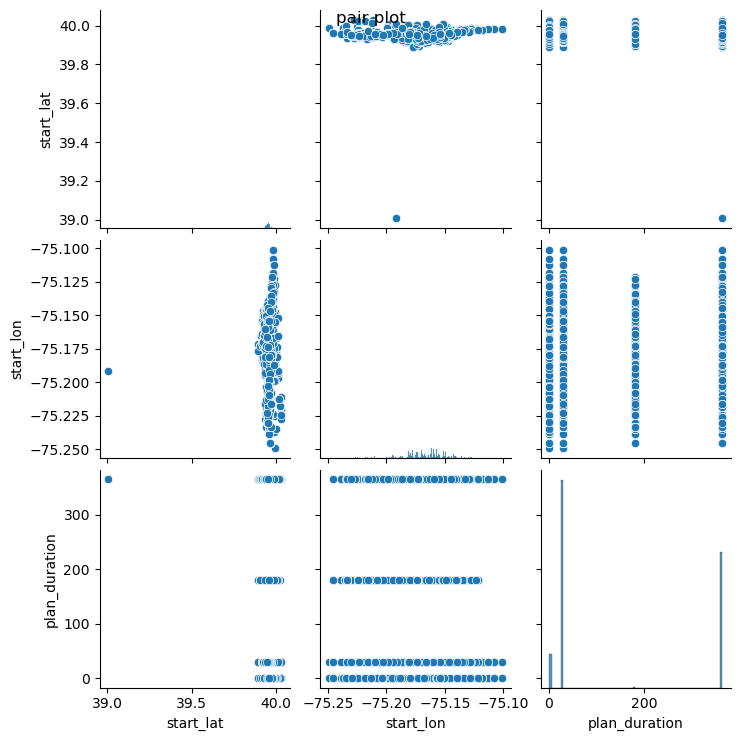

In [10]:
num_predr = ["start_lat", "start_lon", "plan_duration"]
pair_data = train_data.select(num_predr).to_pandas()
sns.pairplot(pair_data)
plt.suptitle("pair plot")
plt.show()

,start_lat,start_lon,plan_duration
start_lat,1.000000,-0.057398,-0.085599
start_lon,-0.057398,1.000000,-0.013955
plan_duration,-0.085599,-0.013955,1.000000


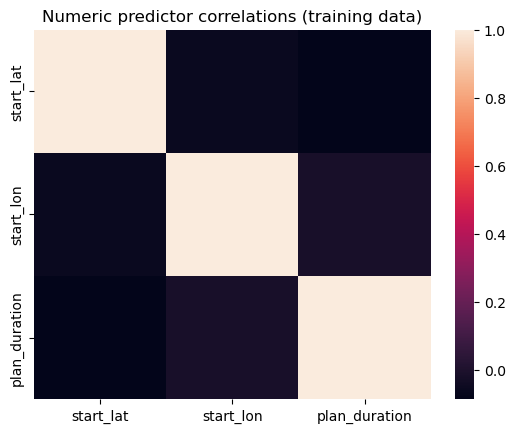

In [11]:
# Pearson correlation uses the full training set.
corrs = train_data.select(num_predr).to_pandas().corr()
display(corrs)
plt.figure()
sns.heatmap(corrs)
plt.title("Numeric predictor correlations (training data)")
plt.show()

**Findings.** The pair plot reveals a potential low-latitude outlier near 39.0. The correlation matrix describes linear relationships among the numeric predictors. Latitude and longitude jointly represent geography, while `plan_duration` is discrete, so correlation alone does not determine which features to remove. We address the low-latitude observation after Section 3.6.

### 3.2 Trip Duration and Target Balance

Inspect typical trip duration, the long tail, and the share of rides above 20 minutes. The histogram focuses on the first 120 minutes for readability; summary statistics include all trips.

In [12]:
display(train_data.select("duration").describe())
display(train_data.group_by("long_ride").agg(pl.len().alias("trips")).sort("long_ride").with_columns((pl.col("trips") / train_data.height * 100).alias("percent")))

statistic,duration
str,f64
"""count""",2.626258e6
"""null_count""",0.0
"""mean""",16.436422
"""std""",51.594396
"""min""",1.0
"""25%""",6.0
"""50%""",10.0
"""75%""",16.0
"""max""",1440.0


long_ride,trips,percent
i8,u32,f64
0,2190691,83.41492
1,435567,16.58508


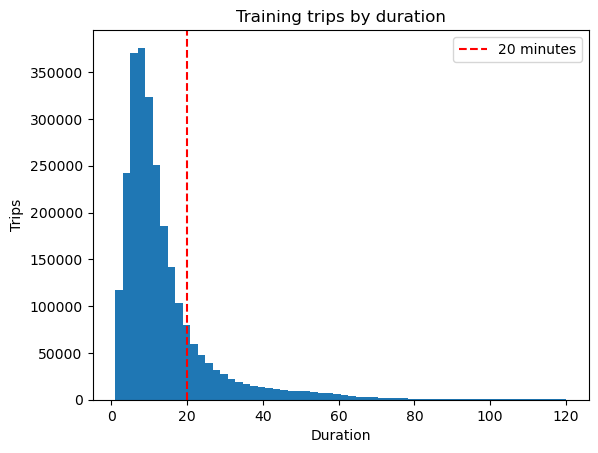

In [13]:
duration = train_data["duration"].to_numpy()
fig, ax = plt.subplots()
ax.hist(duration[duration <= 120], bins=60)
ax.axvline(20, color="red", linestyle="--", label="20 minutes")
ax.set(title="Training trips by duration", xlabel="Duration", ylabel="Trips")
ax.legend()
plt.show()

The histogram and summary describe training-trip duration and the long-ride class balance. Long positive trips are retained for now and will be investigated before any further duration filtering. Duration defines the target and cannot be a predictor.

### 3.3 Bike Type and Passholder Type

Compare long-ride rates and sample counts across checkout-time categories. Counts help distinguish a meaningful group from a small or sparse one.

,bike_type,trips,rate
0,electric,1630889,0.130863
1,standard,995369,0.223178


,passholder_type,trips,rate
0,Indego30,1450607,0.168096
1,Indego365,941820,0.087378
2,Walk-up,123727,0.402717
3,Day Pass,110099,0.541376
4,IndegoFlex,5,0.000000


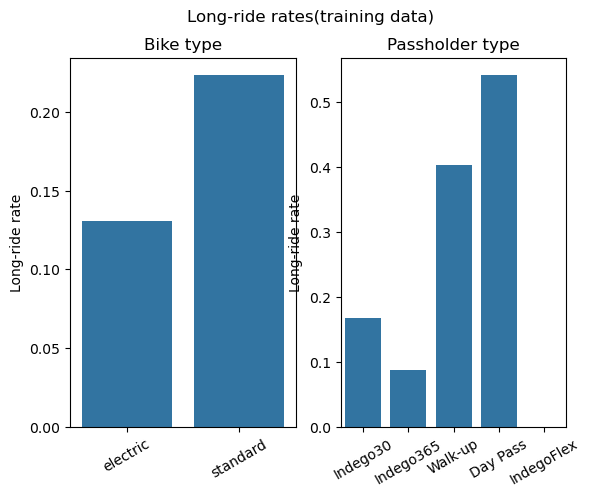

In [14]:
fig, axes = plt.subplots(1, 2)
for ax, col, title in zip(axes, ["bike_type", "passholder_type"], ["Bike type", "Passholder type"]):
    rates = (train_data.group_by(col).agg(pl.len().alias("trips"), pl.col("long_ride").mean().alias("rate"))
             .sort("trips", descending=True).to_pandas())
    sns.barplot(data=rates, x=col, y="rate", ax=ax)
    ax.set(title=title, xlabel="", ylabel="Long-ride rate")
    ax.tick_params(axis="x", rotation=30)
    display(rates[[col, "trips", "rate"]])
fig.suptitle("Long-ride rates(training data)")
plt.show()

**Findings.** The plots compare long-ride rates and sample sizes by bike type and passholder type. `IndegoFlex` appears rarely in the training data; it will be excluded after Section 3.6 as an inactive pass type. `Walk-up` remains its original source category.

### 3.4 Checkout Time

Plot the long-ride rate by checkout hour and day of week using training data. Rates use trips in each time group as the denominator.

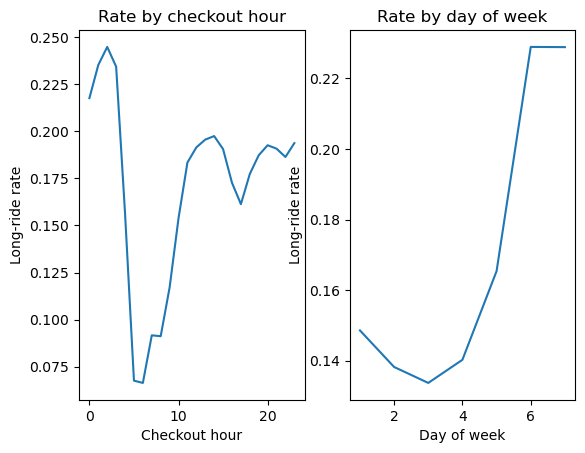

In [15]:
time_data = train_data.with_columns(
    pl.col("start_time").dt.hour().alias("hour"),
    pl.col("start_time").dt.weekday().alias("weekday"),
)
fig, axes = plt.subplots(1, 2)
for ax, col, xlabel in zip(axes, ["hour", "weekday"], ["Checkout hour", "Day of week"]):
    rates = time_data.group_by(col).agg(pl.col("long_ride").mean().alias("rate")).sort(col).to_pandas()
    sns.lineplot(data=rates, x=col, y="rate", ax=ax)
    ax.set(xlabel=xlabel, ylabel="Long-ride rate", title=f"Rate by {xlabel.lower()}")
plt.show()

**Findings.** The plots show how long-ride rates vary by checkout hour and weekday. These patterns can guide the later construction of time features and the planned rush-period comparison.

### 3.5 Starting Stations and Geography

Aggregate trips by starting station to avoid plotting millions of overlapping points. Display stations with at least 100 training trips and valid coordinates; point color represents the station's long-ride rate.

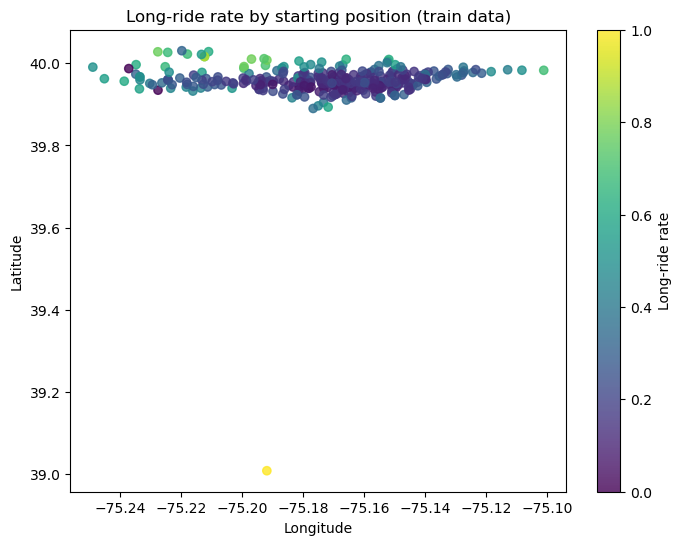

Stations plotted: 316


In [16]:
stations = (train_data.group_by("start_station").agg(
    pl.len().alias("trips"), pl.col("long_ride").mean().alias("rate"),
    pl.col("start_lat").median().alias("latitude"), pl.col("start_lon").median().alias("longitude"),
).to_pandas())
fig, ax = plt.subplots(figsize = (8, 6))
points = ax.scatter(stations["longitude"], stations["latitude"], c=stations["rate"], cmap="viridis", alpha=0.8)
fig.colorbar(points, ax=ax, label="Long-ride rate")
ax.set(title="Long-ride rate by starting position (train data)", xlabel="Longitude", ylabel="Latitude")
plt.show()
print(f"Stations plotted: {len(stations)}")

**Findings.** Station-level rates provide a geographic view of long rides without overplotting individual trips. Sample-size filtering makes the displayed rates easier to interpret. Starting station and coordinates may encode overlapping location information, so their representations should be compared during feature engineering.

### 3.6 Remaining Missingness and Feature Overlap

Confirm that the retained analysis columns have no nulls after cleaning. Compare passholder type and plan duration to inform later feature selection.

In [17]:
train_data.group_by("passholder_type", "plan_duration").agg(pl.len().alias("trips")).sort("trips", descending=True)

passholder_type,plan_duration,trips
str,f64,u32
"""Indego30""",30.0,1448327
"""Indego365""",365.0,940029
"""Walk-up""",1.0,123727
"""Day Pass""",1.0,110099
"""Indego30""",365.0,2280
"""Indego365""",180.0,1791
"""IndegoFlex""",365.0,5


**Findings.** The cleaning rule removes rows with nulls in retained analysis columns. Passholder type and plan duration should be considered together because several passholder categories are strongly associated with particular plan lengths.

### 3.7 EDA-Informed Cleaning

Exclude trips with `IndegoFlex` or `start_lat < 39.1`. Use `plan_duration` to relabel 180-day `Indego365` records as `Indego180`. Keep `plan_duration` until feature preparation in Section 4. Apply the same rules to all periods. The EDA above uses the data before these changes.

In [18]:
pre_eda = data.height

# Apply the same EDA-informed rules to the full dataset and each split.
def apply_eda_exclusions(frame):
    return (
        # exclude outliers of position start_lat < 39.1
        frame.filter((pl.col("passholder_type") != "IndegoFlex") & (pl.col("start_lat") >= 39.1))
        .with_columns(
            # rename column Indego365 with plan_duration = 180 to Indego180
            pl.when((pl.col("passholder_type") == "Indego365") & (pl.col("plan_duration") == 180))
            .then(pl.lit("Indego180"))
            .otherwise(pl.col("passholder_type"))
            .alias("passholder_type")
        )
        # remove duplication column plan_duration
        # .drop("plan_duration")
    )

data = apply_eda_exclusions(data)
train_data = apply_eda_exclusions(train_data)
validation_data = apply_eda_exclusions(validation_data)
test_data = apply_eda_exclusions(test_data)

print(f"Before & after EDA exclusions: {pre_eda:,} & {data.height:,}")
print(f"Rows removed: {pre_eda - data.height:,}")
print(f"Training: {train_data.height:,}; validation: {validation_data.height:,}; test: {test_data.height:,}")

Before & after EDA exclusions: 3,856,591 & 3,856,585
Rows removed: 6
Training: 2,626,252; validation: 689,135; test: 541,198


The exclusion rules remove 6 trips: 5 with `IndegoFlex` and 1 with `start_lat < 39.1`. The 180-day `Indego365` records are relabeled `Indego180`; relabeling does not remove rows. Subsequent analysis uses the updated splits.

**Rechecking plots**

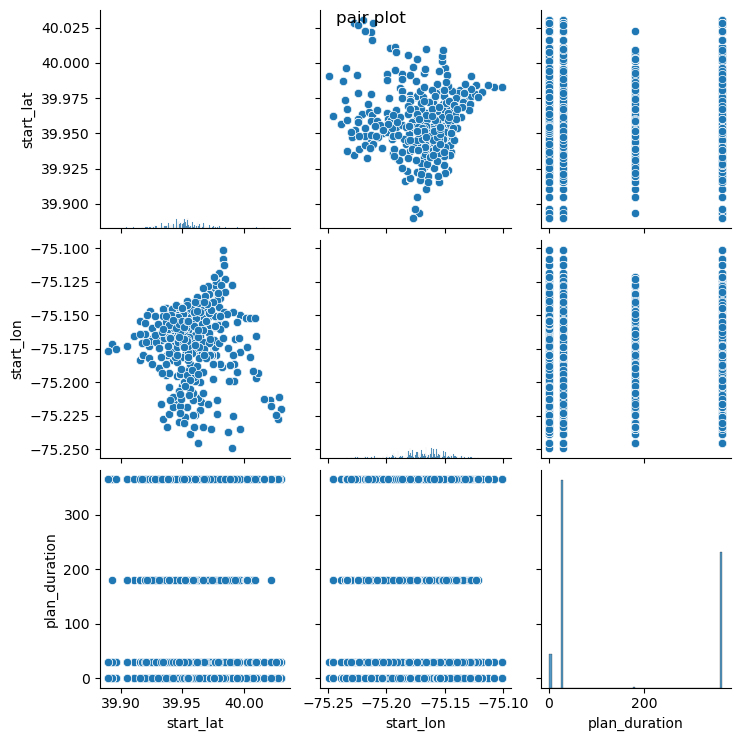

In [19]:
pair_data = train_data.select(num_predr).to_pandas()
sns.pairplot(pair_data)
plt.suptitle("pair plot")
plt.show()

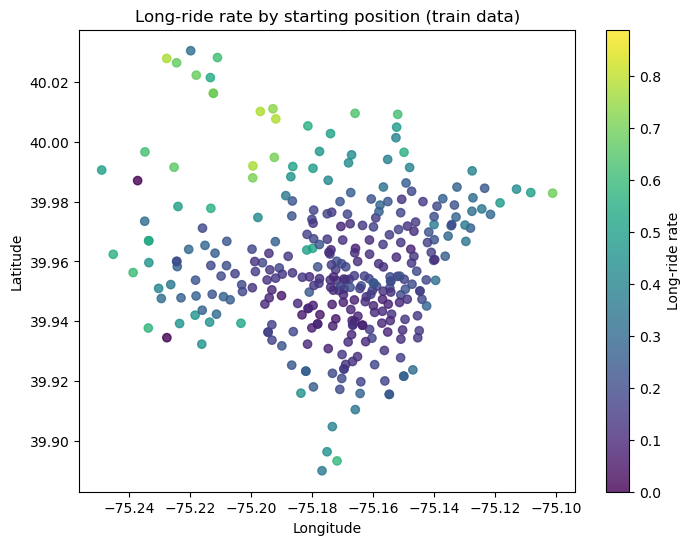

Stations plotted: 315


In [20]:
stations = (train_data.group_by("start_station").agg(
    pl.len().alias("trips"), pl.col("long_ride").mean().alias("rate"),
    pl.col("start_lat").median().alias("latitude"), pl.col("start_lon").median().alias("longitude"),
).to_pandas())
fig, ax = plt.subplots(figsize = (8, 6))
points = ax.scatter(stations["longitude"], stations["latitude"], c=stations["rate"], cmap="viridis", alpha=0.8)
fig.colorbar(points, ax=ax, label="Long-ride rate")
ax.set(title="Long-ride rate by starting position (train data)", xlabel="Longitude", ylabel="Latitude")
plt.show()
print(f"Stations plotted: {len(stations)}")

### 3.7.1 Planning Districts and Station Locations

Plot the training-period long-ride rate at each starting station over the 12 planning districts containing stations in the Indego snapshot.

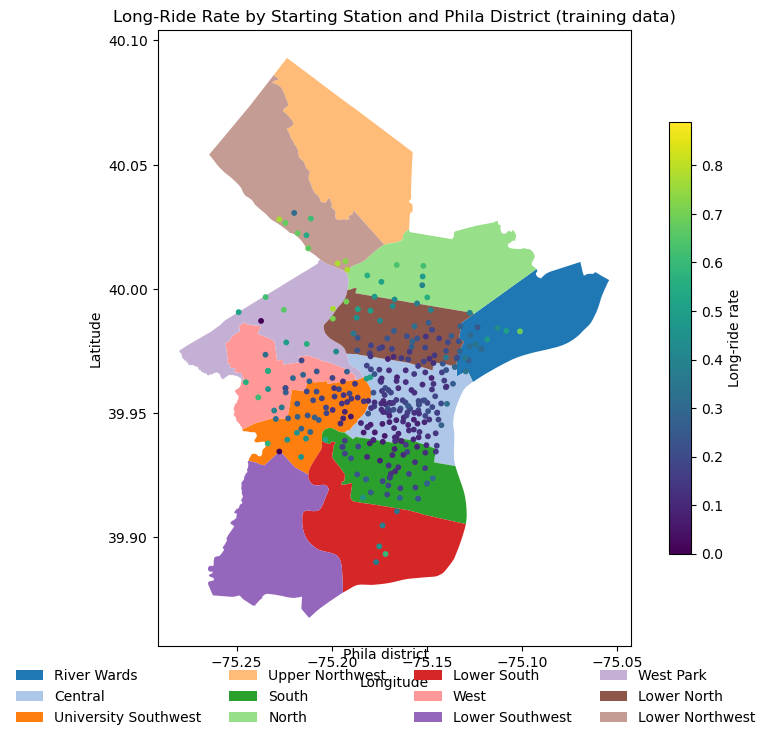

In [21]:
with open("Planning_Districts.geojson", encoding="utf-8-sig") as f:
    district_features = json.load(f)["features"]
with open("Indego_geo.json", encoding="utf-8-sig") as f:
    station_snapshot = json.load(f)

# station geo information in geojson
station_points = np.array([station["geometry"]["coordinates"] for station in station_snapshot["features"]])

# The districts containing stations
phila_dsts = [
    dsts for dsts in district_features
    if PolygonPath(np.asarray(dsts["geometry"]["coordinates"][0])).contains_points(station_points).any()
]
dsts_colors = {dsts["properties"]["dist_name"]: plt.get_cmap("tab20")(i) 
                   for i, dsts in enumerate(phila_dsts)}

fig, ax = plt.subplots(figsize=(10, 8))
for dsts in phila_dsts:
    name = dsts["properties"]["dist_name"]
    ax.add_patch(Polygon(np.asarray(dsts["geometry"]["coordinates"][0]), facecolor=dsts_colors[name]))
ax.set_aspect(1 / np.cos(np.radians(station_points[:, 1].mean())))
ax.set(xlabel="Longitude", ylabel="Latitude", title="Long-Ride Rate by Starting Station and Phila District (training data)")
ax.autoscale_view()

rates_plot = ax.scatter(stations["longitude"], stations["latitude"], c=stations["rate"], cmap="viridis", s=10)
fig.colorbar(rates_plot, ax=ax, label="Long-ride rate", shrink=0.7)
handles = [Patch(facecolor=dsts_colors[d["properties"]["dist_name"]],
                 label=d["properties"]["dist_name"]) for d in phila_dsts]
fig.legend(handles=handles, title="Phila district", loc="lower center", ncol=4, frameon=False)
plt.show()

**Interpretation.** Each point shows a starting station's observed long-ride rate in 2024-2025 training data. The background shows the 12 planning districts that contain stations in the downloaded Indego snapshot.

### 3.8 Hypothesis Testing

#### 3.8.1 Passholder Type

On training data, test whether long-ride rates differ across passholder groups using a permutation test. Report group rates, effect size, null distribution, and p-value.

**Question.** Does the long-ride rate differ across the passholder categories remaining after cleaning?

- **H₀:** All passholder groups have the same long-ride probability.
- **H₁:** At least one passholder group has a different long-ride probability.
- **Test statistic:** The group-size-weighted variance of group long-ride rates around the overall rate, `T = Σ n_g (p_g − p_all)² / N` (larger values support H₁).
- **Null simulation:** Randomly redistribute the observed total number of long rides among fixed passholder group sizes, using a multivariate hypergeometric draw (equivalent to permuting the binary outcomes under exchangeability).

We also report each group's ride count and rate, plus the largest minus smallest group rate in percentage points for practical interpretation. Passholder groups may differ in other characteristics (such as time of day), so the test describes association, not causation.

passholder_type,trips,long_rides,long_ride_pct
str,u32,i64,f64
"""Day Pass""",110099,59605,54.13764
"""Indego180""",1791,281,15.689559
"""Indego30""",1450607,243841,16.809584
"""Indego365""",940028,82012,8.724421
"""Walk-up""",123727,49827,40.271727


Observed weighted rate variance T: 0.010769637
Highest minus lowest passholder long-ride rate: 45.41 percentage points
Permutation p-value (one-sided tail for omnibus T): 0.000200
Significant at Bonferroni-adjusted alpha=0.025: True


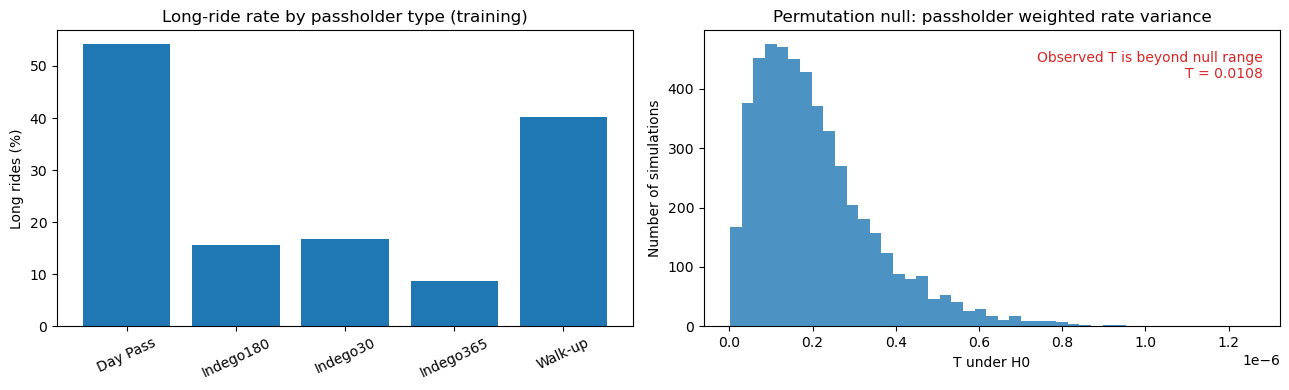

In [22]:
# Omnibus test over all cleaned passholder categories (train only).
N_PERM = 4_999  # Monte Carlo p-value resolution = 1/(N_PERM+1) = 0.0002
ALPHA_ADJUSTED = 0.05 / 2

passholder_summary = (
    train_data.group_by("passholder_type")
    .agg(
        pl.len().alias("trips"),
        pl.col("long_ride").sum().alias("long_rides"),
    )
    .sort("passholder_type")
    .with_columns(
        (100 * pl.col("long_rides") / pl.col("trips")).alias("long_ride_pct")
    )
)
display(passholder_summary)

group_labels = passholder_summary["passholder_type"].to_list()
group_n = passholder_summary["trips"].to_numpy().astype(np.int64)
group_long = passholder_summary["long_rides"].to_numpy().astype(np.int64)
assert len(group_n) >= 2 and np.all(group_n > 0), "Expected at least two nonempty passholder groups"

pooled_rate = group_long.sum() / group_n.sum()
observed_rates = group_long / group_n
passholder_stat = np.sum(group_n * (observed_rates - pooled_rate) ** 2) / group_n.sum()
passholder_rate_range_pp = 100 * (observed_rates.max() - observed_rates.min())

# Conditioning on group sizes and total positives, the following is exactly
# the binary-label permutation null distribution for the table of group counts.
rng_passholder = np.random.default_rng(RANDOM_STATE + 381)
permuted_group_long = rng_passholder.multivariate_hypergeometric(
    group_n, int(group_long.sum()), size=N_PERM
)
permuted_rates = permuted_group_long / group_n[None, :]
passholder_null_stats = (
    np.sum(group_n[None, :] * (permuted_rates - pooled_rate) ** 2, axis=1)
    / group_n.sum()
)
passholder_p_value = (1 + np.count_nonzero(passholder_null_stats >= passholder_stat)) / (N_PERM + 1)

print(f"Observed weighted rate variance T: {passholder_stat:.8g}")
print(f"Highest minus lowest passholder long-ride rate: {passholder_rate_range_pp:.2f} percentage points")
print(f"Permutation p-value (one-sided tail for omnibus T): {passholder_p_value:.6f}")
print(f"Significant at Bonferroni-adjusted alpha={ALPHA_ADJUSTED:.3f}: {passholder_p_value < ALPHA_ADJUSTED}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(group_labels, 100 * observed_rates)
axes[0].set(title="Long-ride rate by passholder type (training)", ylabel="Long rides (%)")
axes[0].tick_params(axis="x", rotation=25)
axes[1].hist(passholder_null_stats, bins=45, alpha=0.8)
axes[1].set(title="Permutation null: passholder weighted rate variance", xlabel="T under H0", ylabel="Number of simulations")
# With millions of trips, the observed statistic may sit well beyond the visible null range.
if passholder_stat <= passholder_null_stats.max() * 1.25:
    axes[1].axvline(passholder_stat, color="tab:red", linestyle="--", label="Observed T")
    axes[1].legend()
else:
    axes[1].text(0.97, 0.93, "Observed T is beyond null range\n" + f"T = {passholder_stat:.3g}",
                 ha="right", va="top", transform=axes[1].transAxes, color="tab:red")
fig.tight_layout()
plt.show()

#### 3.8.2 Morning Versus Evening Rush

On training data, compare 07:00–09:59 and 16:00–18:59 using a two-sided permutation test of the difference in long-ride rates. Report the effect and null distribution.

**Question.** Among trips started during rush windows, is the long-ride rate different in the morning (**07:00–09:59**) and evening (**16:00–18:59**)?

- **H₀:** Within the same calendar date, morning and evening rides have the same long-ride probability (their binary outcomes are exchangeable between rush windows within date).
- **H₁:** The date-adjusted morning-minus-evening long-ride rate differs from zero.
- **Test statistic:** A weighted average of daily differences in long-ride rates. Weight each date by `n_m × n_e / (n_m + n_e)` so that dates with more information contribute more.
- **Null simulation:** For each date, keep the total number of long rides and the numbers of morning/evening trips fixed; reallocate long rides between periods by a hypergeometric draw, then recalculate the weighted difference. Use the **absolute value** of the statistic for a two-sided p-value.

We also report the two *unadjusted* rates for context. Date stratification reduces confounding from day-specific conditions, but repeated riders, location, rider mix, and within-day dependence can still limit exchangeability.

rush_period,trips,long_rides,long_ride_pct
str,u32,i64,f64
"""Evening""",682585,115874,16.975761
"""Morning""",419578,41726,9.944754


Dates with both rush windows: 731
Observed date-adjusted morning minus evening rate: -6.44 percentage points
Two-sided date-stratified permutation p-value: 0.000200
Significant at Bonferroni-adjusted alpha=0.025: True


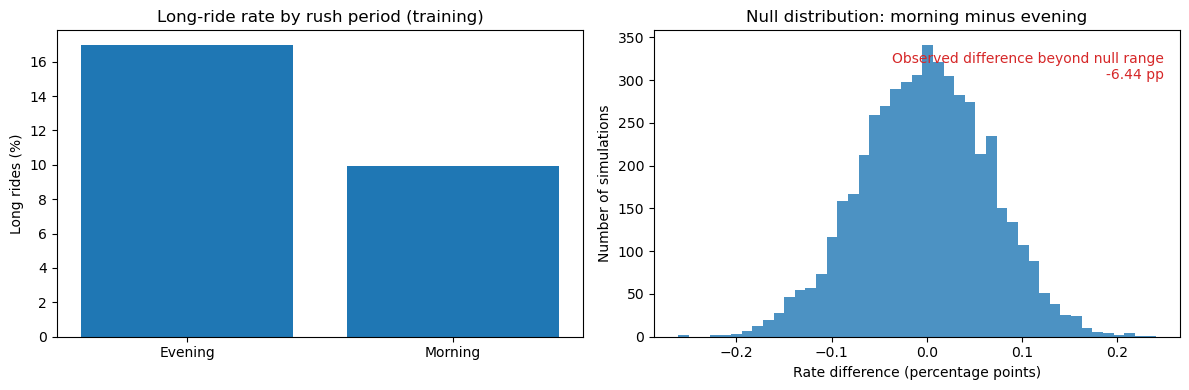

In [23]:
# 3.8.2: Compare 07:00-09:59 versus 16:00-18:59 within each calendar date.
rush_trips = (
    train_data.with_columns(
        pl.col("start_time").dt.hour().alias("checkout_hour"),
        pl.col("start_time").dt.date().alias("checkout_date"),
    )
    .filter(
        ((pl.col("checkout_hour") >= 7) & (pl.col("checkout_hour") < 10))
        | ((pl.col("checkout_hour") >= 16) & (pl.col("checkout_hour") < 19))
    )
    .with_columns(
        pl.when(pl.col("checkout_hour") < 10)
        .then(pl.lit("Morning"))
        .otherwise(pl.lit("Evening"))
        .alias("rush_period")
    )
)

rush_summary = (
    rush_trips.group_by("rush_period")
    .agg(pl.len().alias("trips"), pl.col("long_ride").sum().alias("long_rides"))
    .sort("rush_period")
    .with_columns((100 * pl.col("long_rides") / pl.col("trips")).alias("long_ride_pct"))
)
display(rush_summary)

# A single aggregation per day avoids allocating millions of label arrays per permutation.
per_day = (
    rush_trips.with_columns((pl.col("rush_period") == "Morning").cast(pl.Int64).alias("morning_flag"))
    .group_by("checkout_date")
    .agg(
        pl.col("morning_flag").sum().alias("n_morning"),
        (1 - pl.col("morning_flag")).sum().alias("n_evening"),
        (pl.col("long_ride") * pl.col("morning_flag")).sum().alias("long_morning"),
        (pl.col("long_ride") * (1 - pl.col("morning_flag"))).sum().alias("long_evening"),
    )
    .filter((pl.col("n_morning") > 0) & (pl.col("n_evening") > 0))
    .sort("checkout_date")
)

nm = per_day["n_morning"].to_numpy().astype(np.int64)
ne = per_day["n_evening"].to_numpy().astype(np.int64)
km = per_day["long_morning"].to_numpy().astype(np.int64)
ke = per_day["long_evening"].to_numpy().astype(np.int64)
assert len(nm) > 1, "Need at least two dates with trips in both rush windows"

weights = nm * ne / (nm + ne)
daily_diffs = km / nm - ke / ne
rush_stat = np.average(daily_diffs, weights=weights)  # morning minus evening

# Generate exactly the null count distribution conditional on each date's margins.
long_by_day = km + ke
rng_rush = np.random.default_rng(RANDOM_STATE + 382)
null_long_morning = rng_rush.hypergeometric(
    ngood=long_by_day[None, :],
    nbad=(nm + ne - long_by_day)[None, :],
    nsample=nm[None, :],
    size=(N_PERM, len(nm)),
)
null_daily_diff = null_long_morning / nm[None, :] - (long_by_day[None, :] - null_long_morning) / ne[None, :]
rush_null_stats = np.average(null_daily_diff, weights=weights, axis=1)
rush_p_value = (1 + np.count_nonzero(np.abs(rush_null_stats) >= abs(rush_stat))) / (N_PERM + 1)

print(f"Dates with both rush windows: {len(nm):,}")
print(f"Observed date-adjusted morning minus evening rate: {100 * rush_stat:+.2f} percentage points")
print(f"Two-sided date-stratified permutation p-value: {rush_p_value:.6f}")
print(f"Significant at Bonferroni-adjusted alpha={ALPHA_ADJUSTED:.3f}: {rush_p_value < ALPHA_ADJUSTED}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
period_labels = rush_summary["rush_period"].to_list()
period_pct = rush_summary["long_ride_pct"].to_numpy()
axes[0].bar(period_labels, period_pct)
axes[0].set(title="Long-ride rate by rush period (training)", ylabel="Long rides (%)")
axes[1].hist(100 * rush_null_stats, bins=45, alpha=0.8)
if abs(rush_stat) <= max(abs(rush_null_stats.min()), abs(rush_null_stats.max())) * 1.25:
    axes[1].axvline(100 * rush_stat, color="tab:red", linestyle="--", label="Observed date-adjusted difference")
    axes[1].legend()
else:
    axes[1].text(0.97, 0.93, "Observed difference beyond null range\n" + f"{100 * rush_stat:+.2f} pp",
                 ha="right", va="top", transform=axes[1].transAxes, color="tab:red")
axes[1].set(title="Null distribution: morning minus evening", xlabel="Rate difference (percentage points)", ylabel="Number of simulations")
fig.tight_layout()
plt.show()

#### 3.8.3 Interpretation

We assess the two **pre-specified** tests using a Bonferroni-adjusted alpha of **0.025 each**. The table below summarizes the observed effect, Monte Carlo p-value, and decision. A small p-value provides evidence against the *specified null hypothesis*; it does **not** measure the probability that the null hypothesis is true, and it does not prove causation. Also discuss **effect size** rather than statistical significance alone: millions of trips can make small differences statistically detectable.

**Assumptions.** Both simulations rely on exchangeability of the binary `long_ride` outcomes within their permutation units. The passholder test permutes globally, so time, station, and rider-mix differences can confound the result. The rush-hour test permutes within **calendar day**, reducing day-level confounding but not guaranteeing independence of rides or comparability of who rides in each window. Repeated riders, station differences, trends, and within-day dependence limit the precision of naive trip-level p-values.

**Implication for modeling.** Significant associations support exploring passholder type and checkout time as *candidate predictors*, but predictive usefulness must still be validated on the later period. These group comparisons are **descriptive, not causal**. Robustness checks could stratify further by station or use day/week-clustered resampling; interpret very small p-values with these caveats.

In [24]:
# Summarize the two pre-specified tests. Interpret in light of observational assumptions.
hypothesis_results = pd.DataFrame([
    {
        "Test": "Passholder type (omnibus)",
        "Effect size": f"Group rate range: {passholder_rate_range_pp:.2f} pp",
        "Permutation p-value": passholder_p_value,
        "Decision at alpha=0.025": "Reject H0" if passholder_p_value < ALPHA_ADJUSTED else "Do not reject H0",
    },
    {
        "Test": "Morning vs evening (within-date)",
        "Effect size": f"Adjusted morning-evening: {100 * rush_stat:+.2f} pp",
        "Permutation p-value": rush_p_value,
        "Decision at alpha=0.025": "Reject H0" if rush_p_value < ALPHA_ADJUSTED else "Do not reject H0",
    },
])
display(hypothesis_results)

for row in hypothesis_results.to_dict(orient="records"):
    print(f"{row['Test']}: {row['Decision at alpha=0.025']} "
          f"(Monte Carlo p={row['Permutation p-value']:.6f}; {row['Effect size']}).")
print("Interpretation reminder: Associations do not establish causality; results may reflect confounding and dependence.")

,Test,Effect size,Permutation p-value,Decision at alpha=0.025
0,Passholder type (omnibus),Group rate range: 45.41 pp,0.0002,Reject H0
1,Morning vs evening (within-date),Adjusted morning-evening: -6.44 pp,0.0002,Reject H0


Passholder type (omnibus): Reject H0 (Monte Carlo p=0.000200; Group rate range: 45.41 pp).
Morning vs evening (within-date): Reject H0 (Monte Carlo p=0.000200; Adjusted morning-evening: -6.44 pp).
Interpretation reminder: Associations do not establish causality; results may reflect confounding and dependence.


Both permutation tests revealed statistically significant associations with the probability of a long ride, defined as a trip lasting more than 20 minutes.

**Passholder Type:** The omnibus permutation test produced an observed weighted rate variance of 0.010624 and a Monte Carlo p-value of 0.0002. Since the p-value is below the Bonferroni-adjusted significance level of 0.025, we reject the null hypothesis. Day Pass and Walk-up users exhibited higher long-ride rates of 53.99% and 39.81%, respectively, compared with 8.71% for Indego365 users. The maximum difference across passholder categories was 45.28 percentage points. One possible explanation is that short-term users are more likely to use bike-sharing services for recreational purposes, whereas long-term subscribers may use them for routine commuting.

**Morning versus Evening Rush:** The date-stratified permutation test also yielded a Monte Carlo p-value of 0.0002. The observed long-ride rates were 9.97% during the morning rush and 16.82% during the evening rush. After accounting for date-level differences, the morning-minus-evening rate difference was -6.29 percentage points. Therefore, we reject the null hypothesis and conclude that evening rush trips are associated with a higher probability of being long rides.

**Implications for Modeling:** These findings support the inclusion of passholder type and temporal features in our classification models. However, statistical significance does not necessarily guarantee predictive improvement, which should be assessed through model validation. Furthermore, these results represent observational associations rather than causal relationships. Potential confounding factors and dependence among trips should be acknowledged.

## 4. Feature Engineering and Preprocessing

Build predictors from information available at checkout. Apply the same time transformations to each split and learn categorical encodings from the training data.

### 4.1 Station Region and Checkout-Time Features

Match each distinct historical starting coordinate to one of the 12 planning districts using the district polygons. Join the matched district back to each split by latitude and longitude. This uses the coordinates recorded with the trip. The resulting `station_region` is a categorical predictor.

The EDA showed that long-ride rates vary by hour and weekday. Encode hour, weekday, and month as sine and cosine pairs. Morning rush covers 07:00 to 09:59, and evening rush covers 16:00 to 18:59.

In [25]:
def add_station_region(frame):
    coord = frame.select("start_lat", "start_lon").unique(maintain_order=True)
    stat_pts = coord.select("start_lon", "start_lat").to_numpy()
    regions = np.full(len(coord), None, dtype=object)
    num_match = np.zeros(len(coord), dtype=int)

    for district in phila_dsts:
        rings = district["geometry"]["coordinates"]
        inside = PolygonPath(np.asarray(rings[0])).contains_points(stat_pts)
        for hole in rings[1:]:
            inside &= ~PolygonPath(np.asarray(hole)).contains_points(stat_pts)
        regions[inside] = district["properties"]["dist_name"]
        num_match += inside

    if np.any(num_match != 1):
        raise ValueError(f"{(num_match != 1).sum()} coordinate has no match to any Philadelphia district")

    region_lookup = coord.with_columns(pl.Series("station_region", regions.tolist()))
    return frame.join(region_lookup, on=["start_lat", "start_lon"], how="left", maintain_order="left")

In [26]:
def add_time_features(frame):
    hour = pl.col("start_time").dt.hour()
    weekday = pl.col("start_time").dt.weekday()  # Monday = 1, Sunday = 7
    month = pl.col("start_time").dt.month()

    # Cyclical Encoding
    hour_angle = 2 * np.pi * hour / 24
    weekday_angle = 2 * np.pi * (weekday - 1) / 7
    month_angle = 2 * np.pi * (month - 1) / 12

    return frame.with_columns(
        hour_angle.sin().alias("hour_sin"),
        hour_angle.cos().alias("hour_cos"),
        weekday_angle.sin().alias("weekday_sin"),
        weekday_angle.cos().alias("weekday_cos"),
        month_angle.sin().alias("month_sin"),
        month_angle.cos().alias("month_cos"),
        # weather
        pl.when(month.is_in([12, 1, 2])).then(pl.lit("winter"))
          .when(month.is_in([3, 4, 5])).then(pl.lit("spring"))
          .when(month.is_in([6, 7, 8])).then(pl.lit("summer"))
          .otherwise(pl.lit("fall")).alias("season"),
        # special timing events
        (weekday >= 6).cast(pl.Int8).alias("is_weekend"),
        ((hour >= 7) & (hour < 10)).cast(pl.Int8).alias("is_morning_rush"),
        ((hour >= 16) & (hour < 19)).cast(pl.Int8).alias("is_evening_rush"),
    )

In [27]:
train_features = add_station_region(add_time_features(train_data)).drop("plan_duration")
validation_features = add_station_region(add_time_features(validation_data)).drop("plan_duration")
test_features = add_station_region(add_time_features(test_data)).drop("plan_duration")

### 4.2 Candidate Predictors

Use `station_region` as the location category. `passholder_type` represents the rider's plan after Section 3.7; `plan_duration` is dropped from the feature tables. `long_ride` is the target. Duration, station ID, coordinates, source labels, and raw time are excluded from predictors.

In [32]:
numeric_features = ["hour_sin", "hour_cos", "weekday_sin", "weekday_cos", "month_sin", "month_cos"]
# columns contain only 1 and 0
binary_features = ["is_weekend", "is_morning_rush", "is_evening_rush"]
categorical_features = ["season", "station_region", "passholder_type", "bike_type"]
feature_columns = numeric_features + binary_features + categorical_features

# X_train = train_features.select(feature_columns)
# X_validation = validation_features.select(feature_columns)
# X_test = test_features.select(feature_columns)

X_train = train_features.select(feature_columns).to_pandas()
X_validation = validation_features.select(feature_columns).to_pandas()
X_test = test_features.select(feature_columns).to_pandas()

y_train = train_features["long_ride"]
y_validation = validation_features["long_ride"]
y_test = test_features["long_ride"]

### Save the Prepared Data

Save each chronological split as a Parquet file. Each file includes the prepared columns and `long_ride`. For modeling, use the predictor columns listed above; the files also retain other columns for inspection.

In [33]:
pro_dir = DATA_DIR / "processed"
pro_dir.mkdir(parents=True, exist_ok=True)

train_features.write_parquet(pro_dir / "train.parquet")
validation_features.write_parquet(pro_dir / "validation.parquet")
test_features.write_parquet(pro_dir / "test.parquet")
0
print(f"Saved train, validation, and test data to {pro_dir}")

Saved train, validation, and test data to data/processed


### 4.3 Preprocessing Pipeline

Pass through cyclical features and binary flags. One-hot encode season, station region, passholder type, and bike type. An unseen category is handled by the encoder. Fit the preprocessor inside each model pipeline using training data or the training portion of each fold.

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("binary", "passthrough", binary_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    sparse_threshold=1.0,
)

## 5. Model Implementation and Selection

### 5.1 Logistic Regression Baseline

Compare L1 logistic regression models with `C = 0.01`, `0.1`, and `1.0`. Smaller values of `C` apply stronger regularization. Each model fits its own preprocessing pipeline on the training set and is evaluated on the validation set. Rank models by average precision (AP), and report precision, recall, and F1 at a threshold of 0.50.

In [ ]:
C_values = [0.01, 0.1, 1.0]
l1_models = {}
l1_results = []

for C in C_values:
    logit = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", LogisticRegression(solver="saga", l1_ratio=1.0, C=C, max_iter=500, random_state=RANDOM_STATE))
    ])
    logit.fit(X_train, y_train.to_numpy())
    probabilities = logit.predict_proba(X_validation)[:, 1]
    predictions = (probabilities >= 0.50).astype(np.int8)
    validation_target = y_validation.to_numpy()

    l1_models[C] = logit
    l1_results.append({
        "C": C,
        "AP": average_precision_score(validation_target, probabilities),
        "Precision": precision_score(validation_target, predictions, zero_division=0),
        "Recall": recall_score(validation_target, predictions, zero_division=0),
        "F1": f1_score(validation_target, predictions, zero_division=0),
        "Nonzero coefficients": np.count_nonzero(logit.named_steps["classifier"].coef_),
        "Iterations": logit.named_steps["classifier"].n_iter_[0],
    })

l1_table = pd.DataFrame(l1_results).sort_values("AP", ascending=False)
display(l1_table.set_index("C").round(4))

best_C = l1_table.iloc[0]["C"]
baseline = l1_models[best_C]
print(f"Best validation AP: C = {best_C:g}")

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1175: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1175: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1175: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


In [38]:
baseline_prob = baseline.predict_proba(X_validation)[:, 1]
baseline_pred = (baseline_prob >= 0.50).astype(np.int8)

baseline_confusion = pd.DataFrame(
    confusion_matrix(validation_target, baseline_pred, labels=[0, 1]),
    index=["Actual short", "Actual long"],
    columns=["Predicted short", "Predicted long"],
)
display(baseline_confusion)

,Predicted short,Predicted long
Actual short,551216,13489
Actual long,106810,17620


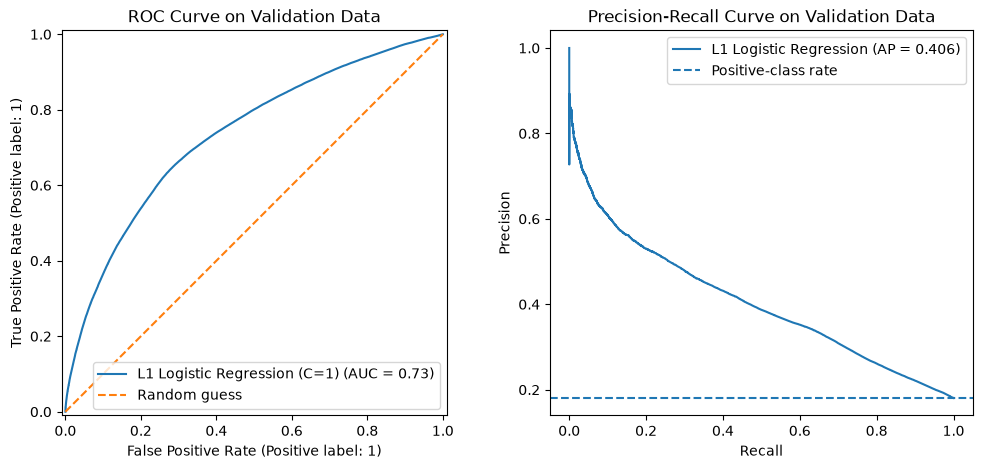

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_predictions(
    validation_target, baseline_prob,
    name=f"L1 Logistic Regression (C={best_C:g})", ax=ax[0],)
ax[0].plot([0, 1], [0, 1], "--",label="Random guess")
ax[0].set_title("ROC Curve on Validation Data")
ax[0].legend()

precision, recall, _ = precision_recall_curve(validation_target, baseline_prob)
ap = average_precision_score(validation_target, baseline_prob)
ax[1].plot(recall, precision, label=f"L1 Logistic Regression (AP = {ap:.3f})")
ax[1].axhline(np.mean(validation_target), linestyle="--", label="Positive-class rate")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve on Validation Data")
ax[1].legend()

plt.show()

**Validation findings.** After running the models, compare validation AP, precision, recall, F1, and the number of nonzero coefficients. Check for convergence warnings before interpreting the comparison.

### 5.2 Random Forest

Train a tree ensemble and consider tree count, depth, leaf size, feature subsampling, and class weights.

#### 5.2.1 Time-Aware Cross Validation Setup

We use a 4-fold expanding-window cross-validation strategy within the 2024–2025 training period to tune the Random Forest hyperparameters.

Each fold uses all preceding quarters for training and one complete subsequent quarter for validation. This preserves chronological order and allows us to evaluate model performance across different seasons.

We compare hyperparameter configurations based on mean Average Precision (AP) across folds, while also considering the standard deviation of AP to assess temporal stability.

In [49]:
from datetime import datetime

# Expanding-window CV within 2024–2025
cv_folds = [
    ("2025 Q1", datetime(2025, 1, 1), datetime(2025, 4, 1)),
    ("2025 Q2", datetime(2025, 4, 1), datetime(2025, 7, 1)),
    ("2025 Q3", datetime(2025, 7, 1), datetime(2025, 10, 1)),
    ("2025 Q4", datetime(2025, 10, 1), datetime(2026, 1, 1)),
]

# Check the size of each fold
fold_sizes = []

for name, val_start, val_end in cv_folds:
    fold_train = train_features.filter(
        pl.col("start_time") < val_start
    )
    fold_val = train_features.filter(
        (pl.col("start_time") >= val_start) &
        (pl.col("start_time") < val_end)
    )

    fold_sizes.append({
        "Fold": name,
        "Train Size": fold_train.height,
        "Validation Size": fold_val.height
    })

display(pd.DataFrame(fold_sizes))

,Fold,Train Size,Validation Size
0,2025 Q1,1268136,201579
1,2025 Q2,1469715,365752
2,2025 Q3,1835467,465447
3,2025 Q4,2300914,325338


#### 5.2.2 Random Forest Hyperparameter Tuning


We perform a grid search over 12 Random Forest hyperparameter configurations, varying max_depth (8, 12, 20), min_samples_leaf (20, 50), and class_weight (None, balanced_subsample). We keep n_estimators=50 and max_features="sqrt" fixed during this initial search.

Each configuration is evaluated using the four expanding-window folds defined in Section 5.2.1, resulting in 48 model fits. For each fold, we train a new preprocessing and modeling pipeline using only the preceding quarters and evaluate it on the subsequent quarter.

We record Average Precision (AP), precision, recall, F1-score, and training time. We use mean AP across folds as the primary criterion for hyperparameter selection, while considering variability across quarters, classification performance, and computational cost.

In [54]:
# TODO: Implement this section.
rf_param_grid = {
    "max_depth": [8, 12, 20],
    "min_samples_leaf": [20, 50],
    "class_weight": [None, "balanced_subsample"]
}

rf_cv_configs = list(ParameterGrid(rf_param_grid))

print(f"Total configurations: {len(rf_cv_configs)}")

rf_cv_results = []

for i, params in enumerate(rf_cv_configs):
    for fold_name, val_start, val_end in cv_folds:

        # Split training and validation data for this fold
        fold_train = train_features.filter(
            pl.col("start_time") < val_start
        )

        fold_val = train_features.filter(
            (pl.col("start_time") >= val_start) &
            (pl.col("start_time") < val_end)
        )

        X_fold_train = fold_train.select(feature_columns)
        y_fold_train = fold_train["long_ride"].to_numpy()

        X_fold_val = fold_val.select(feature_columns)
        y_fold_val = fold_val["long_ride"].to_numpy()

        # Build a new pipeline for each fold
        rf_model = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("classifier", RandomForestClassifier(
                n_estimators=50,
                max_features="sqrt",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                **params
            ))
        ])

        # Train
        start = time.perf_counter()
        rf_model.fit(X_fold_train, y_fold_train)
        train_time = time.perf_counter() - start

        # Predict and evaluate
        rf_prob = rf_model.predict_proba(X_fold_val)[:, 1]
        rf_pred = (rf_prob >= 0.5).astype(int)

        f1 = f1_score(y_fold_val, rf_pred, zero_division=0)
        ap = average_precision_score(y_fold_val, rf_prob)
        precision = precision_score(y_fold_val, rf_pred, zero_division=0)
        recall = recall_score(y_fold_val, rf_pred, zero_division=0)

        rf_cv_results.append({
            "Config": i + 1,
            "Fold": fold_name,
            "max_depth": params["max_depth"],
            "min_samples_leaf": params["min_samples_leaf"],
            "class_weight": str(params["class_weight"]),
            "AP": ap,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Time": train_time
        })

rf_cv_df = pd.DataFrame(rf_cv_results)
display(rf_cv_df.round(4))

Total configurations: 12


,Config,Fold,max_depth,min_samples_leaf,class_weight,AP,Precision,Recall,F1,Time
0,1,2025 Q1,8,20,None,0.3882,0.6875,0.0668,0.1217,3.7391
1,1,2025 Q2,8,20,None,0.4371,0.6695,0.0777,0.1393,4.6376
2,1,2025 Q3,8,20,None,0.4117,0.6809,0.0696,0.1263,5.7113
3,1,2025 Q4,8,20,None,0.3642,0.6738,0.0633,0.1158,7.1236
4,2,2025 Q1,8,50,None,0.3875,0.6722,0.0680,0.1235,3.5464
5,2,2025 Q2,8,50,None,0.4366,0.6688,0.0793,0.1418,4.3931
6,2,2025 Q3,8,50,None,0.4112,0.6698,0.0717,0.1296,5.6428
7,2,2025 Q4,8,50,None,0.3645,0.6815,0.0603,0.1108,7.1474
8,3,2025 Q1,12,20,None,0.3922,0.6159,0.1025,0.1757,8.4690
9,3,2025 Q2,12,20,None,0.4404,0.5897,0.1596,0.2512,9.3001


#### 5.2.3 Cross-Validation Results

In [64]:
rf_cv_summary = (
    rf_cv_df.groupby(
        ["Config", "max_depth", "min_samples_leaf", "class_weight"],
        as_index=False
    )
    .agg(
        mean_AP=("AP", "mean"),
        std_AP=("AP", "std"),
        mean_Precision=("Precision", "mean"),
        mean_Recall=("Recall", "mean"),
        mean_F1=("F1", "mean"),
        total_time=("Time", "sum")
    )
    .sort_values("mean_AP", ascending=False)
)

display(rf_cv_summary.round(4))

,Config,max_depth,min_samples_leaf,class_weight,mean_AP,std_AP,mean_Precision,mean_Recall,mean_F1,total_time
2,3,12,20,None,0.4044,0.0300,0.6106,0.1182,0.1963,47.7779
3,4,12,50,None,0.4044,0.0303,0.6105,0.1154,0.1921,44.8191
5,6,20,50,None,0.4038,0.0300,0.5950,0.1296,0.2113,184.4988
8,9,12,20,balanced_subsample,0.4014,0.0307,0.3285,0.6366,0.4334,57.3891
4,5,20,20,None,0.4010,0.0300,0.5863,0.1324,0.2139,290.7440
11,12,20,50,balanced_subsample,0.4009,0.0306,0.3240,0.6440,0.4309,197.4492
9,10,12,50,balanced_subsample,0.4006,0.0302,0.3287,0.6374,0.4337,52.3567
0,1,8,20,None,0.4003,0.0313,0.6779,0.0694,0.1258,21.2115
1,2,8,50,None,0.3999,0.0310,0.6731,0.0698,0.1264,20.7297
10,11,20,20,balanced_subsample,0.3986,0.0304,0.3236,0.6406,0.4297,328.8643


**Hyperparameter Effects:**
Across the 12 Random Forest configurations, models with max_depth=12 achieved the highest mean Average Precision (AP), approximately 0.4044. Increasing the maximum depth to 20 did not meaningfully improve AP, despite substantially increasing training time. Similarly, changing min_samples_leaf from 20 to 50 had minimal impact on performance.These results suggest that increasing tree complexity does not necessarily improve generalization in our dataset.

We selected Configurations 3 and 9 for further comparison because they share the same hyperparameters (max_depth=12, min_samples_leaf=20) and differ only in class_weight.

**Class Weighting and Precision-Recall Trade-off:**
Config 3 (Unweighted): Mean AP = 0.4044, Mean F1 = 0.1963.
Config 9 (Balanced): Mean AP = 0.4014, Mean F1 = 0.4334.
The unweighted model consistently achieved slightly higher AP across all four validation quarters. However, the balanced model achieved substantially higher recall (0.6366 vs. 0.1182) and F1-score at the default decision threshold of 0.5, at the cost of lower precision.
Since F1 depends on the decision threshold(currently it is 0.5), further threshold tuning is necessary before determining which configuration performs better for our classification objective.

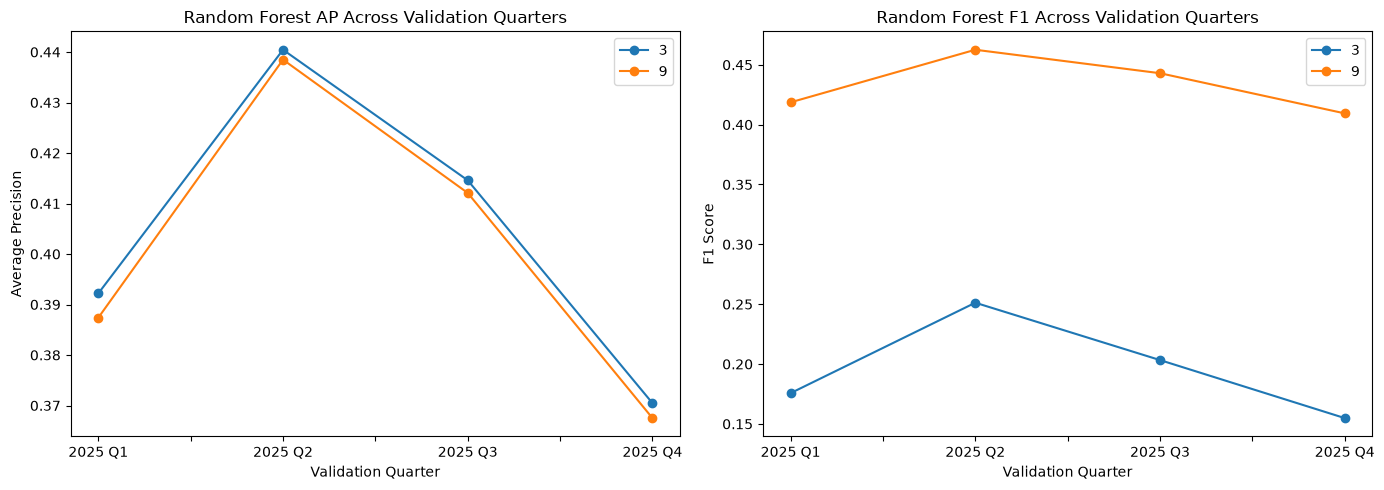

In [65]:
selected_configs = rf_cv_df[
    rf_cv_df["Config"].isin([3, 9])
]

# AP data
ap_by_quarter = selected_configs.pivot(
    index="Fold",
    columns="Config",
    values="AP"
).reindex(["2025 Q1", "2025 Q2", "2025 Q3", "2025 Q4"])

ap_by_quarter = ap_by_quarter.rename(
    columns={4: "RF Unweighted", 10: "RF Balanced"}
)

# F1 data
f1_by_quarter = selected_configs.pivot(
    index="Fold",
    columns="Config",
    values="F1"
).reindex(["2025 Q1", "2025 Q2", "2025 Q3", "2025 Q4"])

f1_by_quarter = f1_by_quarter.rename(
    columns={4: "RF Unweighted", 10: "RF Balanced"}
)

# Plot side by side
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ap_by_quarter.plot(marker="o", ax=ax[0])
ax[0].set_title("Random Forest AP Across Validation Quarters")
ax[0].set_xlabel("Validation Quarter")
ax[0].set_ylabel("Average Precision")
ax[0].legend()

f1_by_quarter.plot(marker="o", ax=ax[1])
ax[1].set_title("Random Forest F1 Across Validation Quarters")
ax[1].set_xlabel("Validation Quarter")
ax[1].set_ylabel("F1 Score")
ax[1].legend()

plt.tight_layout()
plt.show()

Both configurations showed similar temporal patterns, achieving their highest AP in 2025 Q2 and lowest AP in 2025 Q4. This pattern can be observed in other configurations as well.

To investigate these differences, we examined the proportion of long-duration rides across validation quarters:

In [66]:
for name, val_start, val_end in cv_folds:
    fold_val = train_features.filter(
        (pl.col("start_time") >= val_start) &
        (pl.col("start_time") < val_end)
    )

    print(
        f"{name}: "
        f"{fold_val['long_ride'].mean():.4f}"
    )

2025 Q1: 0.1362
2025 Q2: 0.1889
2025 Q3: 0.1839
2025 Q4: 0.1470


In [67]:
rf_cv_round1_df = rf_cv_df.copy()

#### Tree Count Refinement

In [68]:
# Tree Count Refinement
rf_tree_grid = {
    "n_estimators": [50, 100, 150],
    "class_weight": [None, "balanced_subsample"]
}

rf_tree_configs = list(ParameterGrid(rf_tree_grid))

print(f"Total configurations: {len(rf_tree_configs)}")

rf_tree_results = []

for i, params in enumerate(rf_tree_configs):
    for fold_name, val_start, val_end in cv_folds:

        # Split training and validation data for this fold
        fold_train = train_features.filter(
            pl.col("start_time") < val_start
        )

        fold_val = train_features.filter(
            (pl.col("start_time") >= val_start) &
            (pl.col("start_time") < val_end)
        )

        X_fold_train = fold_train.select(feature_columns)
        y_fold_train = fold_train["long_ride"].to_numpy()

        X_fold_val = fold_val.select(feature_columns)
        y_fold_val = fold_val["long_ride"].to_numpy()

        # Build a new pipeline for each fold
        rf_model = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("classifier", RandomForestClassifier(
                max_depth=12,
                min_samples_leaf=20,
                max_features="sqrt",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                **params
            ))
        ])

        # Train
        start = time.perf_counter()
        rf_model.fit(X_fold_train, y_fold_train)
        train_time = time.perf_counter() - start

        # Predict and evaluate
        rf_prob = rf_model.predict_proba(X_fold_val)[:, 1]
        rf_pred = (rf_prob >= 0.5).astype(int)

        ap = average_precision_score(y_fold_val, rf_prob)
        precision = precision_score(y_fold_val, rf_pred, zero_division=0)
        recall = recall_score(y_fold_val, rf_pred, zero_division=0)
        f1 = f1_score(y_fold_val, rf_pred, zero_division=0)

        rf_tree_results.append({
            "Config": 3 if params["class_weight"] is None else 9,
            "Fold": fold_name,
            "max_depth": 12,
            "min_samples_leaf": 20,
            "class_weight": str(params["class_weight"]),
            "n_estimators": params["n_estimators"],
            "AP": ap,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Time": train_time
        })

rf_tree_df = pd.DataFrame(rf_tree_results)
display(rf_tree_df.round(4))

Total configurations: 6


,Config,Fold,max_depth,min_samples_leaf,class_weight,n_estimators,AP,Precision,Recall,F1,Time
0,3,2025 Q1,12,20,None,50,0.3922,0.6159,0.1025,0.1757,8.9222
1,3,2025 Q2,12,20,None,50,0.4404,0.5897,0.1596,0.2512,9.2416
2,3,2025 Q3,12,20,None,50,0.4146,0.5977,0.1225,0.2033,12.9495
3,3,2025 Q4,12,20,None,50,0.3705,0.6392,0.0881,0.1549,18.2866
4,3,2025 Q1,12,20,None,100,0.3926,0.6175,0.1012,0.1739,16.6802
5,3,2025 Q2,12,20,None,100,0.4401,0.5867,0.1651,0.2577,19.5557
6,3,2025 Q3,12,20,None,100,0.4150,0.6003,0.1192,0.1989,23.0300
7,3,2025 Q4,12,20,None,100,0.3704,0.6366,0.0876,0.1540,30.3384
8,3,2025 Q1,12,20,None,150,0.3930,0.6183,0.1010,0.1737,23.1881
9,3,2025 Q2,12,20,None,150,0.4405,0.5981,0.1492,0.2388,27.2619


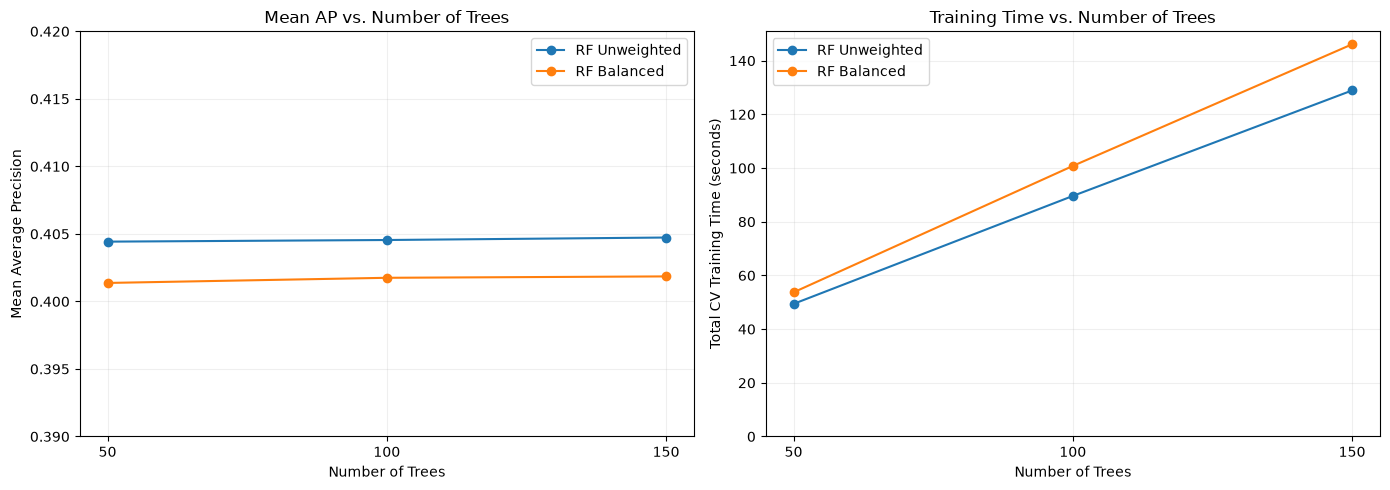

In [69]:
# Summarize tree count refinement results
rf_tree_plot = (
    rf_tree_df.groupby(
        ["Config", "n_estimators"],
        as_index=False
    )
    .agg(
        mean_AP=("AP", "mean"),
        mean_F1=("F1", "mean"),
        total_time=("Time", "sum")
    )
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for config, label in [(3, "RF Unweighted"), (9, "RF Balanced")]:
    data = rf_tree_plot[
        rf_tree_plot["Config"] == config
    ].sort_values("n_estimators")

    # Mean AP
    ax[0].plot(
        data["n_estimators"],
        data["mean_AP"],
        marker="o",
        label=label
    )

    # Training time
    ax[1].plot(
        data["n_estimators"],
        data["total_time"],
        marker="o",
        label=label
    )

ax[0].set_title("Mean AP vs. Number of Trees")
ax[0].set_xlabel("Number of Trees")
ax[0].set_ylabel("Mean Average Precision")
ax[0].set_ylim(0.39, 0.42)
ax[0].legend()

ax[1].set_title("Training Time vs. Number of Trees")
ax[1].set_xlabel("Number of Trees")
ax[1].set_ylabel("Total CV Training Time (seconds)")
ax[1].set_ylim(bottom=0)
ax[1].legend()

for axis in ax:
    axis.set_xticks([50, 100, 150])
    axis.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Increasing n_estimators from 50 to 150 resulted in only marginal improvements in mean Average Precision (AP) for both Random Forest candidates.

For the unweighted model, mean AP increased from 0.4044 to 0.4047, while the balanced model improved from 0.4014 to 0.4019. However, these improvements came with substantially increased training time, and F1-scores did not consistently improve.

Therefore, we retain n_estimators=50 for both candidates to balance predictive performance and computational efficiency.

#### 5.2.4 RF Validation Performance

We evaluate both Random Forest candidates on the chronological validation set (2026 Q1–Q2), using Average Precision (AP), precision, recall, and F1-score.

We initially use a fixed decision threshold of 0.5 to compare the effects of class weighting on classification performance. Final threshold tuning and model selection will be conducted later.

In [70]:
# Final Random Forest candidates
rf_candidate_params = {
    "RF Unweighted": {
        "max_depth": 12,
        "min_samples_leaf": 20,
        "class_weight": None
    },
    "RF Balanced": {
        "max_depth": 12,
        "min_samples_leaf": 20,
        "class_weight": "balanced_subsample"
    }
}

rf_candidate_models = {}
rf_training_times = {}

for name, params in rf_candidate_params.items():

    rf_model = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=50,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params
        ))
    ])

    start = time.perf_counter()

    rf_model.fit(X_train, y_train.to_numpy())

    train_time = time.perf_counter() - start

    rf_candidate_models[name] = rf_model
    rf_training_times[name] = train_time

    print(f"{name}: {train_time:.2f} seconds")

RF Unweighted: 19.35 seconds
RF Balanced: 20.67 seconds


In [71]:
y_val = y_validation.to_numpy()

rf_validation_results = []
rf_validation_predictions = {}

for name, model in rf_candidate_models.items():

    # Predict probabilities and labels
    rf_prob = model.predict_proba(X_validation)[:, 1]
    rf_pred = (rf_prob >= 0.5).astype(int)

    # Store predictions for later visualization
    rf_validation_predictions[name] = {
        "prob": rf_prob,
        "pred": rf_pred
    }

    # Evaluate
    rf_validation_results.append({
        "Model": name,
        "AP": average_precision_score(y_val, rf_prob),
        "Precision": precision_score(y_val, rf_pred, zero_division=0),
        "Recall": recall_score(y_val, rf_pred, zero_division=0),
        "F1": f1_score(y_val, rf_pred, zero_division=0)
    })

rf_validation_df = pd.DataFrame(rf_validation_results)
display(rf_validation_df.round(4))

,Model,AP,Precision,Recall,F1
0,RF Unweighted,0.4157,0.5980,0.1386,0.2250
1,RF Balanced,0.4128,0.3531,0.6175,0.4493


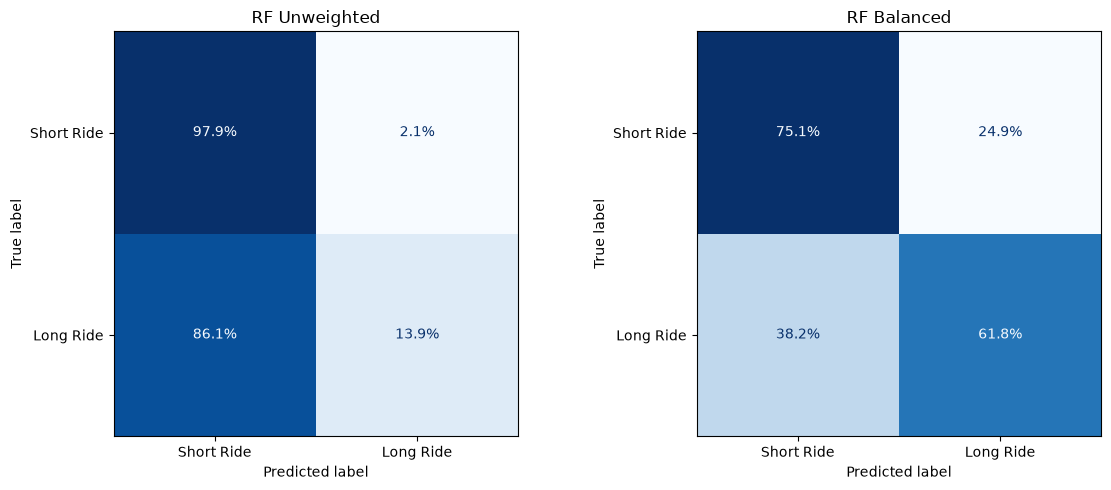

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, results) in zip(axes, rf_validation_predictions.items()):

    cm = confusion_matrix(
        y_val,
        results["pred"],
        labels=[0, 1],
        normalize="true"
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Short Ride", "Long Ride"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format=".1%"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

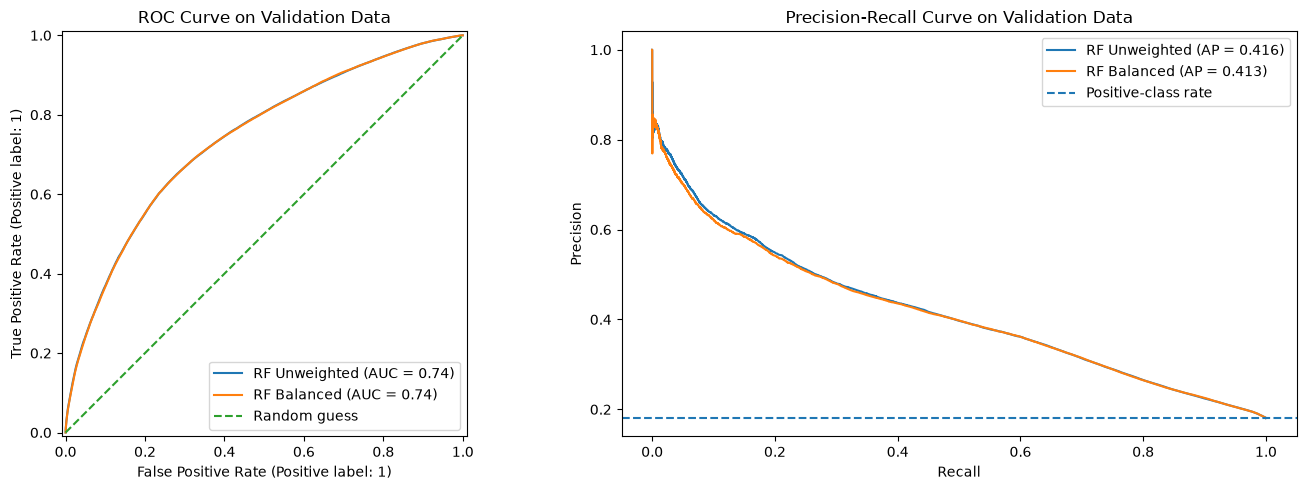

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, results in rf_validation_predictions.items():
    rf_prob = results["prob"]

    # ROC Curve
    RocCurveDisplay.from_predictions(
        y_val,
        rf_prob,
        name=name,
        ax=axes[0]
    )

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(
        y_val, rf_prob
    )

    ap = average_precision_score(y_val, rf_prob)

    axes[1].plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

# ROC random-guess baseline
axes[0].plot(
    [0, 1], [0, 1],
    "--",
    label="Random guess"
)

axes[0].set_title("ROC Curve on Validation Data")
axes[0].legend()

# PR positive-class baseline
axes[1].axhline(
    y=y_val.mean(),
    linestyle="--",
    label="Positive-class rate"
)

axes[1].set_title("Precision-Recall Curve on Validation Data")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.3 Gradient Boosting

Use histogram gradient boosting to predict whether a ride will last more than 20 minutes. The **Baseline predictors** are the same 13 input columns used by the Logistic Regression baseline in Section 5.1. They include six cyclical time features, three time flags, season, station region, passholder type, and bike type. Logistic Regression one-hot encodes the categories. Histogram boosting encodes them as categorical inputs for the trees. Compare this feature set with one that also includes starting latitude, starting longitude, checkout hour, weekday, and month.

#### 5.3.1 Checkout Features and Model Capacity

Test 15 and 31 maximum leaves with otherwise identical settings. Treat nominal predictors as categorical inputs, fit the encoder inside each fold, and disable internal early stopping so model selection follows the chronological folds.

In [86]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

def gb_hist_checkout_features(frame):
    start = pl.col("start_time").dt
    return frame.select(
        *feature_columns,
        "start_lat",
        "start_lon",
        start.hour().alias("checkout_hour"),
        start.weekday().alias("checkout_weekday"),
        start.month().alias("checkout_month"),
    ).to_pandas()

gb_hist_base_numeric = numeric_features + binary_features
gb_hist_feature_sets = {
    "Baseline predictors": gb_hist_base_numeric,
    "Coordinates and calendar": gb_hist_base_numeric + [
        "start_lat", "start_lon", "checkout_hour", "checkout_weekday", "checkout_month",
    ],
}

def gb_hist_pipeline(feature_set, max_leaf_nodes):
    numeric = gb_hist_feature_sets[feature_set]
    encoder = ColumnTransformer([
        ("numeric", "passthrough", numeric),
        ("categorical", OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=np.nan
        ), categorical_features),
    ])
    categorical_indices = list(range(len(numeric), len(numeric) + len(categorical_features)))
    return Pipeline([
        ("preprocess", encoder),
        ("classifier", HistGradientBoostingClassifier(
            categorical_features=categorical_indices,
            learning_rate=0.08,
            max_iter=150,
            max_leaf_nodes=max_leaf_nodes,
            min_samples_leaf=100,
            l2_regularization=2.0,
            early_stopping=False,
            random_state=RANDOM_STATE,
        )),
    ])

#### 5.3.2 Expanding-Window Comparison and Threshold Selection

Use four expanding-window folds, one per quarter of 2025. In each fold, draw a reproducible sample of up to 100,000 trips from the preceding quarters and score the entire next quarter. Select the candidate with the highest mean average precision (AP). Use that candidate's pooled out-of-fold predictions to choose the cutoff with the highest F1 before scoring the 2026 validation data.

In [98]:
gb_hist_folds = [
    ("2025 Q1", np.datetime64("2025-01-01"), np.datetime64("2025-04-01")),
    ("2025 Q2", np.datetime64("2025-04-01"), np.datetime64("2025-07-01")),
    ("2025 Q3", np.datetime64("2025-07-01"), np.datetime64("2025-10-01")),
    ("2025 Q4", np.datetime64("2025-10-01"), np.datetime64("2026-01-01")),
]
gb_hist_train = gb_hist_checkout_features(train_features)
gb_hist_y = y_train.to_numpy()
gb_hist_times = train_features["start_time"].to_numpy()
gb_hist_cv_rows = gb_hist_times >= gb_hist_folds[0][1]
gb_hist_candidates = [
    (features, leaves)
    for features in gb_hist_feature_sets
    for leaves in (15, 31)
]
gb_hist_oof = {
    candidate: np.full(len(gb_hist_y), np.nan)
    for candidate in gb_hist_candidates
}
gb_hist_scores = []

with threadpool_limits(limits=4, user_api="openmp"):
    for gb_hist_quarter, gb_hist_start, gb_hist_end in gb_hist_folds:
        gb_hist_eligible = np.flatnonzero(gb_hist_times < gb_hist_start)
        gb_hist_fit_rows = np.sort(np.random.default_rng(RANDOM_STATE).choice(
            gb_hist_eligible, size=min(100_000, len(gb_hist_eligible)), replace=False
        ))
        gb_hist_fold_rows = np.flatnonzero(
            (gb_hist_times >= gb_hist_start) & (gb_hist_times < gb_hist_end)
        )
        gb_hist_fold_train = gb_hist_train.iloc[gb_hist_fit_rows]
        gb_hist_fold_validation = gb_hist_train.iloc[gb_hist_fold_rows]
        for gb_hist_features, gb_hist_leaves in gb_hist_candidates:
            gb_hist_fold_model = gb_hist_pipeline(gb_hist_features, gb_hist_leaves)
            gb_hist_fold_model.fit(gb_hist_fold_train, gb_hist_y[gb_hist_fit_rows])
            gb_hist_prob = gb_hist_fold_model.predict_proba(gb_hist_fold_validation)[:, 1]
            gb_hist_oof[gb_hist_features, gb_hist_leaves][gb_hist_fold_rows] = gb_hist_prob
            gb_hist_scores.append({
                "Features": gb_hist_features,
                "Max leaves": gb_hist_leaves,
                "Fold": gb_hist_quarter,
                "AP": average_precision_score(gb_hist_y[gb_hist_fold_rows], gb_hist_prob),
            })
        print(f"Completed {gb_hist_quarter}")

gb_hist_cv = pd.DataFrame(gb_hist_scores)
gb_hist_summary = (
    gb_hist_cv.pivot(index=["Features", "Max leaves"], columns="Fold", values="AP")
    .assign(mean_ap=lambda table: table.mean(axis=1))
    .reset_index()
    .sort_values(["mean_ap", "Max leaves"], ascending=[False, True])
    .set_index(["Features", "Max leaves"])
)
gb_hist_best = gb_hist_summary.index[0]
display(gb_hist_summary.round(4))

gb_hist_oof_prob = gb_hist_oof[gb_hist_best][gb_hist_cv_rows]
gb_hist_precision, gb_hist_recall, gb_hist_thresholds = precision_recall_curve(
    gb_hist_y[gb_hist_cv_rows], gb_hist_oof_prob
)
gb_hist_pr_sum = gb_hist_precision[:-1] + gb_hist_recall[:-1]
gb_hist_f1_curve = np.divide(
    2 * gb_hist_precision[:-1] * gb_hist_recall[:-1],
    gb_hist_pr_sum,
    out=np.zeros_like(gb_hist_pr_sum),
    where=gb_hist_pr_sum > 0,
)
gb_hist_threshold = float(gb_hist_thresholds[gb_hist_f1_curve.argmax()])
print(f"Selected {gb_hist_best[0]}, {gb_hist_best[1]} leaves, and cutoff {gb_hist_threshold:.4f}.")

Completed 2025 Q1
Completed 2025 Q2
Completed 2025 Q3
Completed 2025 Q4


Fold                                 2025 Q1  2025 Q2  ...  2025 Q4  mean_ap
Features                 Max leaves                    ...                  
Coordinates and calendar 31           0.4214   0.4631  ...   0.3920   0.4305
                         15           0.4185   0.4638  ...   0.3920   0.4301
Baseline predictors      15           0.3894   0.4358  ...   0.3656   0.4014
                         31           0.3859   0.4368  ...   0.3655   0.4006

[4 rows x 5 columns]

Selected Coordinates and calendar, 31 leaves, and cutoff 0.2293.


##### Cross-Validation Performance by Quarter

Compare the four feature and tree-capacity combinations using quarterly AP and F1 at the common cutoff of 0.50. The AP panel shows the ranking metric used for model selection.

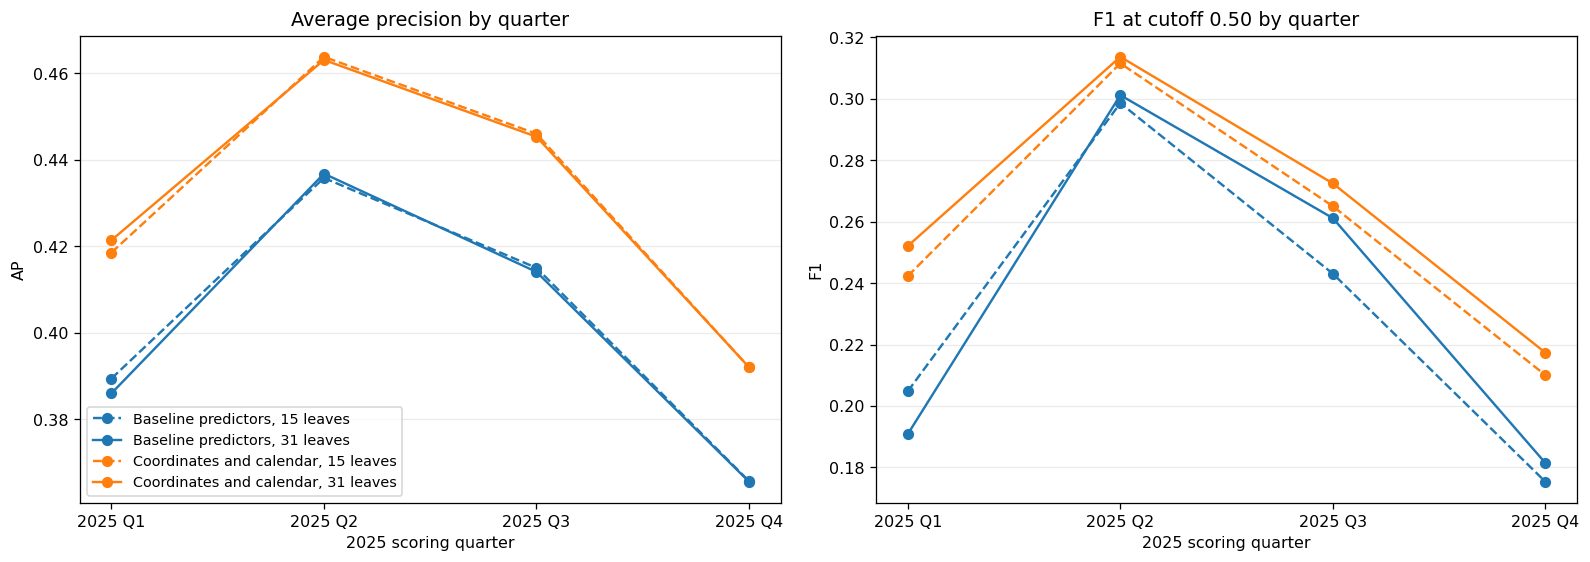

In [99]:
gb_hist_cv_f1 = []
for gb_hist_quarter, gb_hist_start, gb_hist_end in gb_hist_folds:
    gb_hist_quarter_mask = (gb_hist_times >= gb_hist_start) & (gb_hist_times < gb_hist_end)
    for gb_hist_candidate, gb_hist_fold_prob in gb_hist_oof.items():
        gb_hist_cv_f1.append({
            "Features": gb_hist_candidate[0],
            "Max leaves": gb_hist_candidate[1],
            "Fold": gb_hist_quarter,
            "F1": f1_score(
                gb_hist_y[gb_hist_quarter_mask],
                gb_hist_fold_prob[gb_hist_quarter_mask] >= 0.50,
                zero_division=0,
            ),
        })

gb_hist_fold_order = [name for name, _, _ in gb_hist_folds]
gb_hist_fig, gb_hist_axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for gb_hist_ax, gb_hist_values, gb_hist_metric, gb_hist_title in [
    (gb_hist_axes[0], gb_hist_cv, "AP", "Average precision by quarter"),
    (gb_hist_axes[1], pd.DataFrame(gb_hist_cv_f1), "F1", "F1 at cutoff 0.50 by quarter"),
]:
    for (gb_hist_features, gb_hist_leaves), gb_hist_scores_by_fold in gb_hist_values.groupby(
        ["Features", "Max leaves"], sort=False
    ):
        gb_hist_series = gb_hist_scores_by_fold.set_index("Fold")[gb_hist_metric].reindex(gb_hist_fold_order)
        gb_hist_ax.plot(
            gb_hist_series.index, gb_hist_series,
            color={"Baseline predictors": "tab:blue", "Coordinates and calendar": "tab:orange"}[gb_hist_features],
            linestyle={15: "--", 31: "-"}[gb_hist_leaves], marker="o",
            label=f"{gb_hist_features}, {gb_hist_leaves} leaves",
        )
    gb_hist_ax.set(title=gb_hist_title, xlabel="2025 scoring quarter", ylabel=gb_hist_metric)
    gb_hist_ax.grid(axis="y", alpha=0.25)

gb_hist_axes[0].legend(loc="best", fontsize=9)
gb_hist_fig.tight_layout()
plt.show()

##### Feature Gains and Cutoff Selection

The left panel subtracts AP for the Baseline predictors from AP for the expanded feature set within each quarter and tree size. The right panel shows how precision, recall, and F1 vary with the cutoff on the winning configuration's pooled 2025 out-of-fold predictions.

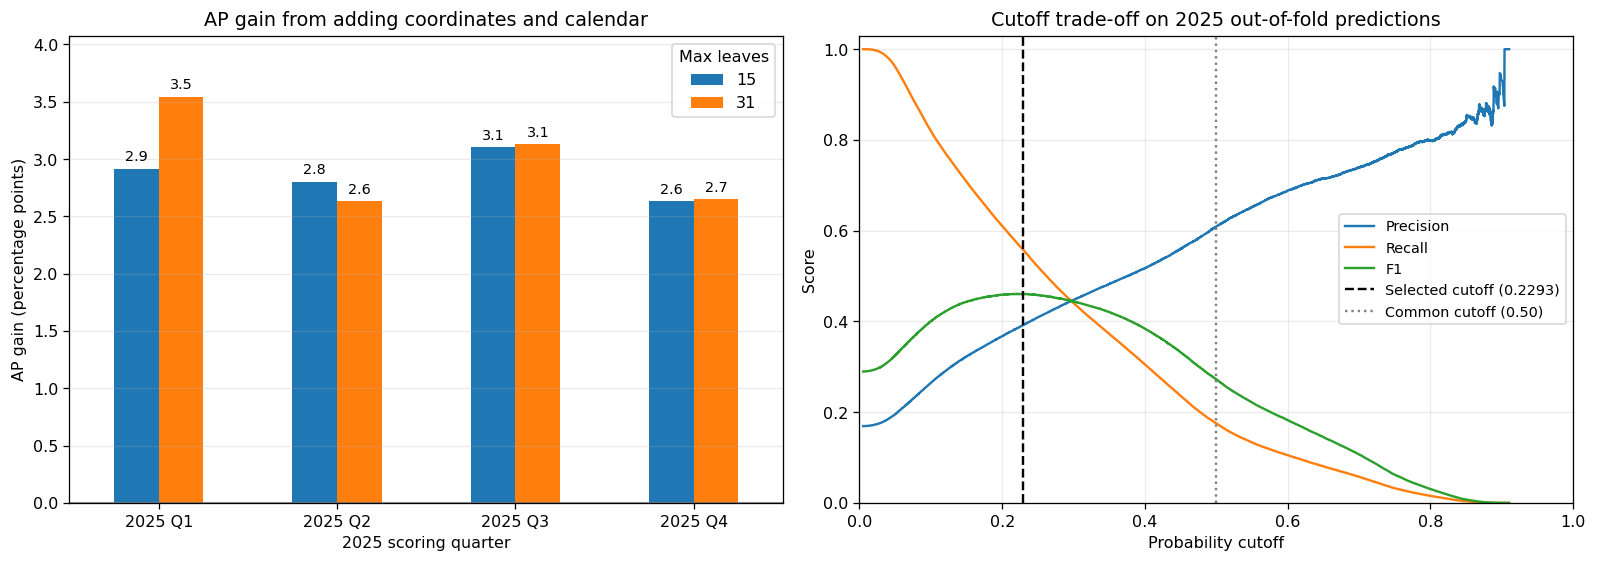

In [100]:
gb_hist_ap_by_feature = gb_hist_cv.pivot(
    index=["Fold", "Max leaves"], columns="Features", values="AP"
)
gb_hist_ap_gain = (
    100 * (gb_hist_ap_by_feature["Coordinates and calendar"] - gb_hist_ap_by_feature["Baseline predictors"])
).unstack("Max leaves").reindex(gb_hist_fold_order)

gb_hist_fig, gb_hist_axes = plt.subplots(1, 2, figsize=(14, 5))
gb_hist_ap_gain.plot.bar(
    ax=gb_hist_axes[0], rot=0, color=["tab:blue", "tab:orange"],
)
for gb_hist_bars in gb_hist_axes[0].containers:
    gb_hist_axes[0].bar_label(gb_hist_bars, fmt="%.1f", padding=3, fontsize=9)
gb_hist_axes[0].axhline(0, color="gray", linewidth=1)
gb_hist_axes[0].set(
    title="AP gain from adding coordinates and calendar",
    xlabel="2025 scoring quarter", ylabel="AP gain (percentage points)",
)
gb_hist_axes[0].margins(y=0.15)
gb_hist_axes[0].legend(title="Max leaves")
gb_hist_axes[0].grid(axis="y", alpha=0.25)

for gb_hist_label, gb_hist_curve in [
    ("Precision", gb_hist_precision[:-1]),
    ("Recall", gb_hist_recall[:-1]),
    ("F1", gb_hist_f1_curve),
]:
    gb_hist_axes[1].plot(gb_hist_thresholds, gb_hist_curve, label=gb_hist_label)
gb_hist_axes[1].axvline(
    gb_hist_threshold, linestyle="--", color="black",
    label=f"Selected cutoff ({gb_hist_threshold:.4f})",
)
gb_hist_axes[1].axvline(0.50, linestyle=":", color="gray", label="Common cutoff (0.50)")
gb_hist_axes[1].set(
    title="Cutoff trade-off on 2025 out-of-fold predictions",
    xlabel="Probability cutoff", ylabel="Score", xlim=(0, 1), ylim=(0, 1.03),
)
gb_hist_axes[1].grid(alpha=0.25)
gb_hist_axes[1].legend(loc="best", fontsize=9)
gb_hist_fig.tight_layout()
plt.show()

#### 5.3.3 Full Training Refit and 2026 Validation

Refit the selected configuration on all 2024–2025 trips. Report 2026 Q1–Q2 AP and classification metrics at the common cutoff of 0.50 and at the cutoff selected from 2025 predictions. AP measures ranking and stays the same at either cutoff. The tuned-cutoff F1 shows how the chosen operating point transfers to 2026. A like-for-like selection by tuned F1 would also require tuning the baseline's cutoff.

In [88]:
gb_hist_model = gb_hist_pipeline(*gb_hist_best)
gb_hist_refit_start = time.perf_counter()
with threadpool_limits(limits=4, user_api="openmp"):
    gb_hist_model.fit(gb_hist_train, gb_hist_y)
    gb_hist_validation_prob = gb_hist_model.predict_proba(
        gb_hist_checkout_features(validation_features)
    )[:, 1]

gb_hist_validation_y = y_validation.to_numpy()
gb_hist_ap = average_precision_score(gb_hist_validation_y, gb_hist_validation_prob)
gb_hist_rows = []
for gb_hist_cutoff_name, gb_hist_cutoff in [
    ("Common cutoff", 0.50), ("Cutoff selected on 2025 folds", gb_hist_threshold),
]:
    gb_hist_predictions = gb_hist_validation_prob >= gb_hist_cutoff
    gb_hist_rows.append({
        "Operating point": gb_hist_cutoff_name,
        "Threshold": gb_hist_cutoff,
        "AP": gb_hist_ap,
        "Precision": precision_score(gb_hist_validation_y, gb_hist_predictions, zero_division=0),
        "Recall": recall_score(gb_hist_validation_y, gb_hist_predictions, zero_division=0),
        "F1": f1_score(gb_hist_validation_y, gb_hist_predictions, zero_division=0),
    })

gb_hist_validation = pd.DataFrame(gb_hist_rows).set_index("Operating point")
gb_hist_validation_pred = gb_hist_validation_prob >= gb_hist_threshold
print(f"Refitted and scored in {time.perf_counter() - gb_hist_refit_start:,.1f} seconds.")
display(gb_hist_validation.round(4))

Refitted and scored in 30.2 seconds.


,Threshold,AP,Precision,Recall,F1
Operating point,,,,,
Common cutoff,0.5000,0.451,0.6175,0.1885,0.2888
Cutoff selected on 2025 folds,0.2293,0.451,0.3957,0.5806,0.4706


##### Validation Confusion Matrices and Ranking Curves

Each confusion matrix shows percentages within actual ride classes. The ROC and precision–recall curves use probabilities from the refitted model. Markers on the precision–recall curve show the common cutoff and the cutoff chosen on the 2025 folds.

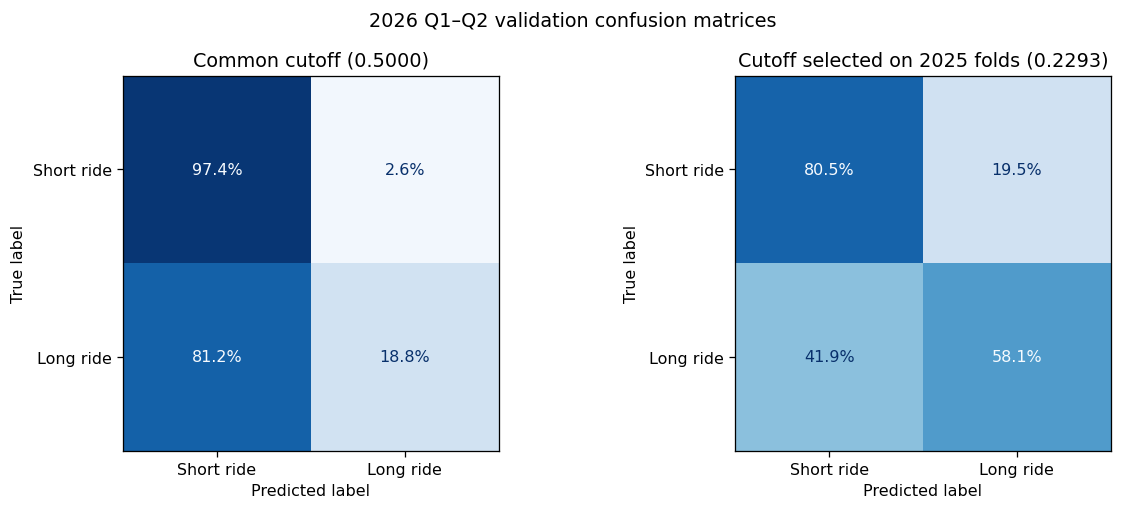

In [94]:
gb_hist_fig, gb_hist_axes = plt.subplots(1, 2, figsize=(11, 4.5))
for gb_hist_ax, (gb_hist_point, gb_hist_metrics) in zip(gb_hist_axes, gb_hist_validation.iterrows()):
    gb_hist_cutoff = gb_hist_metrics["Threshold"]
    gb_hist_cm = confusion_matrix(
        gb_hist_validation_y, gb_hist_validation_prob >= gb_hist_cutoff,
        labels=[0, 1], normalize="true",
    )
    ConfusionMatrixDisplay(
        confusion_matrix=gb_hist_cm, display_labels=["Short ride", "Long ride"],
    ).plot(ax=gb_hist_ax, cmap="Blues", colorbar=False, values_format=".1%")
    gb_hist_ax.images[0].set_clim(0, 1)
    gb_hist_ax.set_title(f"{gb_hist_point} ({gb_hist_cutoff:.4f})")

gb_hist_fig.suptitle("2026 Q1–Q2 validation confusion matrices")
gb_hist_fig.tight_layout()
plt.show()

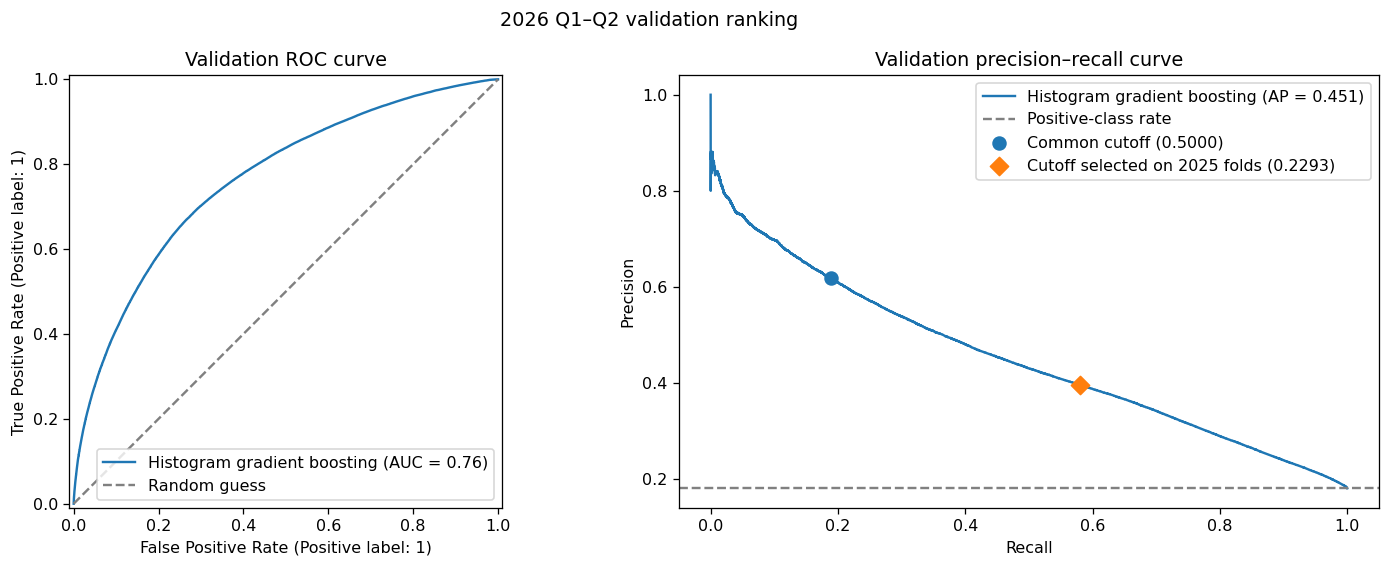

In [95]:
gb_hist_fig, gb_hist_axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(
    gb_hist_validation_y, gb_hist_validation_prob,
    name="Histogram gradient boosting", ax=gb_hist_axes[0],
)
gb_hist_axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
gb_hist_axes[0].set_title("Validation ROC curve")
gb_hist_axes[0].legend(loc="lower right")

gb_hist_val_precision, gb_hist_val_recall, _ = precision_recall_curve(
    gb_hist_validation_y, gb_hist_validation_prob,
)
gb_hist_axes[1].plot(
    gb_hist_val_recall, gb_hist_val_precision,
    label=f"Histogram gradient boosting (AP = {gb_hist_ap:.3f})",
)
gb_hist_axes[1].axhline(
    gb_hist_validation_y.mean(), linestyle="--", color="gray", label="Positive-class rate",
)
for gb_hist_marker, (gb_hist_point, gb_hist_metrics) in zip(
    ("o", "D"), gb_hist_validation.iterrows()
):
    gb_hist_axes[1].scatter(
        gb_hist_metrics["Recall"], gb_hist_metrics["Precision"], marker=gb_hist_marker,
        s=65, zorder=3, label=f"{gb_hist_point} ({gb_hist_metrics['Threshold']:.4f})",
    )
gb_hist_axes[1].set(title="Validation precision–recall curve", xlabel="Recall", ylabel="Precision")
gb_hist_axes[1].legend(loc="upper right")

gb_hist_fig.suptitle("2026 Q1–Q2 validation ranking")
gb_hist_fig.tight_layout()
plt.show()

##### Validation Scores by Actual Ride Class

Each histogram shows the percentage of its ride class in each probability bin. The overlap near the cutoffs shows why catching more long rides also flags more short rides.

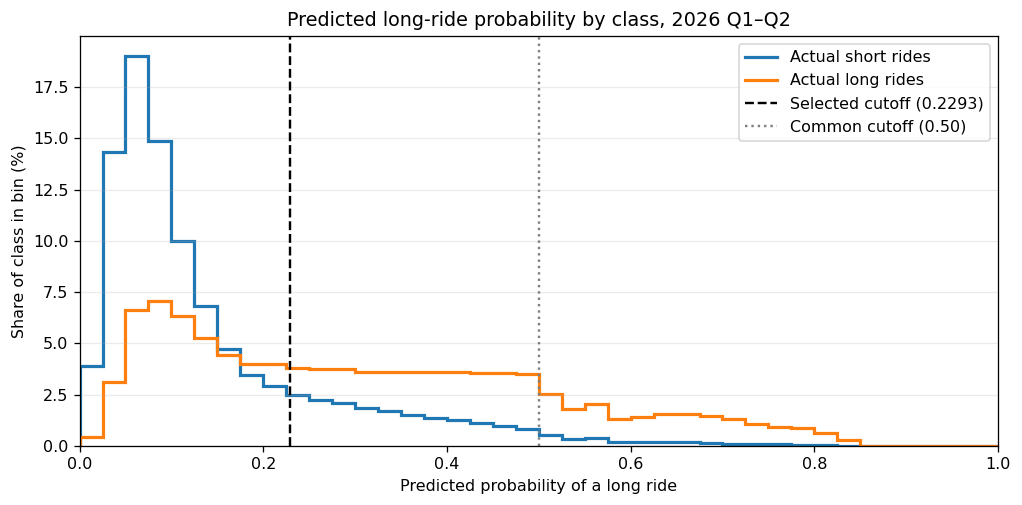

In [104]:
gb_hist_fig, gb_hist_ax = plt.subplots(figsize=(9, 4.5))
gb_hist_bins = np.linspace(0, 1, 41)
for gb_hist_class_label, gb_hist_class_name, gb_hist_color in [
    (0, "Actual short rides", "tab:blue"),
    (1, "Actual long rides", "tab:orange"),
]:
    gb_hist_class_prob = gb_hist_validation_prob[gb_hist_validation_y == gb_hist_class_label]
    gb_hist_counts, _ = np.histogram(gb_hist_class_prob, bins=gb_hist_bins)
    gb_hist_ax.stairs(
        100 * gb_hist_counts / gb_hist_class_prob.size, gb_hist_bins,
        linewidth=2, color=gb_hist_color, label=gb_hist_class_name,
    )

gb_hist_ax.axvline(
    gb_hist_threshold, linestyle="--", color="black",
    label=f"Selected cutoff ({gb_hist_threshold:.4f})",
)
gb_hist_ax.axvline(0.50, linestyle=":", color="gray", label="Common cutoff (0.50)")
gb_hist_ax.set(
    title="Predicted long-ride probability by class, 2026 Q1–Q2",
    xlabel="Predicted probability of a long ride", ylabel="Share of class in bin (%)",
    xlim=(0, 1),
)
gb_hist_ax.grid(axis="y", alpha=0.25)
gb_hist_ax.legend()
gb_hist_fig.tight_layout()
plt.show()

#### 5.3.4 Findings

**Feature comparison.** With 31 maximum leaves, adding starting coordinates and calendar features lifted mean AP from 0.4006 to 0.4305. The expanded feature set improved AP in all four scoring quarters at that capacity.

**Validation ranking.** Histogram boosting reached AP of 0.4510 on 2026 Q1–Q2, up from 0.4057 for Logistic Regression. At the shared 0.50 cutoff, F1 rose from 0.2266 for Logistic Regression to 0.2888 for histogram boosting.

**Operating point.** The cutoff of 0.2293, selected using the 2025 out-of-fold predictions, yielded 39.6% precision, 58.1% recall, and F1 of 0.4706 in 2026 Q1–Q2. The 2026 Q3 test split is reserved for final evaluation.

### 5.4 Hyperparameter Tuning and Model Selection

#### 5.4.1 Time-Aware Validation

If cross-validating within 2024–2025, use expanding time windows; do not use random stratified folds.

In [ ]:
# TODO: Implement this section.


#### 5.4.2 Compare on Validation

Compare precision, recall, F1, PR-AUC, and confusion matrices. Use validation F1 as the proposed selection metric, with recall and stability considered.

In [ ]:
# TODO: Implement this section.


#### 5.4.3 Select the Decision Threshold

Choose a threshold using validation only, then freeze the model and threshold before final testing.

In [ ]:
# TODO: Implement this section.


## 6. Results and Discussion

### 6.1 Final Test-Set Evaluation

#### 6.1.1 Evaluate the Frozen Model

Evaluate on 2026 Q3 only after selection. Report precision, recall, F1, PR-AUC, confusion matrix, and precision-recall curve.

In [ ]:
# TODO: Implement this section.


#### 6.1.2 Error Analysis

Summarize false positives and false negatives without using test outcomes to retune the model.

In [ ]:
# TODO: Implement this section.


### 6.2 Bootstrap Confidence Intervals

#### 6.2.1 Resampling

Bootstrap final test predictions for intervals for precision, recall, F1, and PR-AUC; document the resampling unit and any dependence assumptions.

In [ ]:
# TODO: Implement this section.


#### 6.2.2 Interpretation

Report 95% confidence intervals and interpret uncertainty rather than using them to select the model.

In [ ]:
# TODO: Implement this section.


### 6.3 Prediction Interpretation

#### 6.3.1 Logistic Regression

Interpret coefficients and odds ratios with attention to interactions and correlated features.

In [ ]:
# TODO: Implement this section.


#### 6.3.2 Tree Ensembles

Compare feature importance with permutation importance; describe how correlated predictors can share importance.

In [ ]:
# TODO: Implement this section.


#### 6.3.3 Connect the Findings

Relate descriptive patterns, hypothesis tests, predictive importance, and temporal generalization without claiming causation.

In [ ]:
# TODO: Implement this section.


### 6.4 Challenges

#### 6.4.1 Data Validity

Document data-quality rules and their effect on the dataset.

In [ ]:
# TODO: Implement this section.


#### 6.4.2 Temporal Distribution Shift

Compare training and later periods and discuss differences that affect generalization.

In [ ]:
# TODO: Implement this section.


#### 6.4.3 Class Imbalance

Assess prevalence and use precision, recall, F1, and PR-AUC rather than accuracy alone.

In [ ]:
# TODO: Implement this section.


#### 6.4.4 Feature Redundancy and High Cardinality

Discuss overlapping predictors and station categories in modeling and interpretation.

In [ ]:
# TODO: Implement this section.


### 6.5 Conclusion

#### 6.5.1 Findings and Implications

After the analysis, answer the research questions, compare models, identify useful checkout-time information, and discuss fleet-turnover implications.

In [ ]:
# TODO: Implement this section.


#### 6.5.2 Limitations and Next Steps

Document limitations, uncertainty, and follow-up work based on observed results.

In [ ]:
# TODO: Implement this section.
